# 1 Wavelet Transform for Data Security

## 1.2 Wavelet-Based Encryption

### 1.2.2 Encryption Algorithms

**1. Selective Encryption**

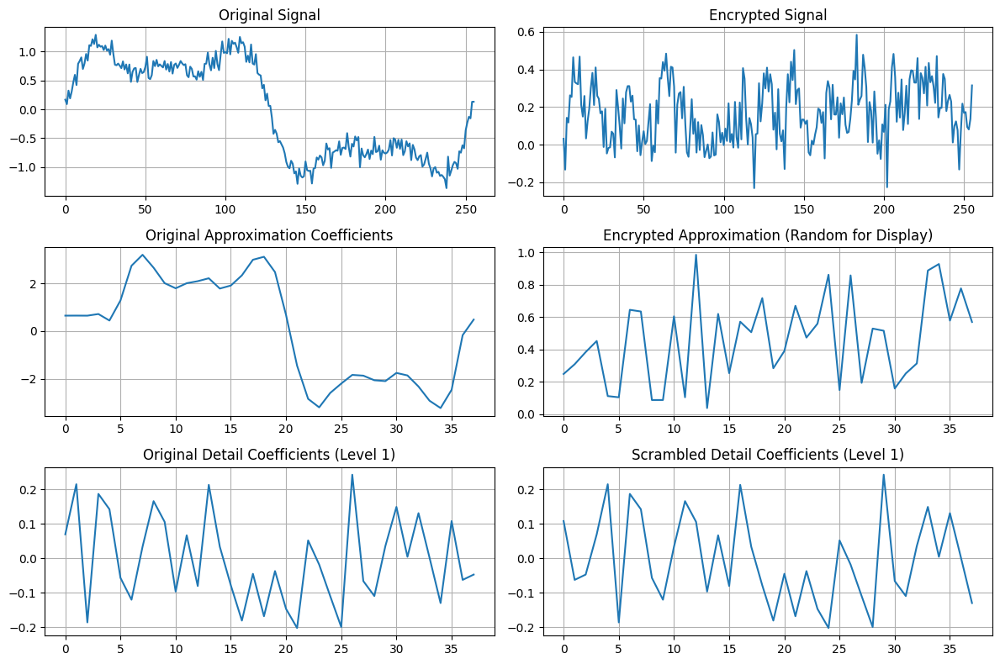

Max Reconstruction Error: 8.88e-16
Mean Reconstruction Error (MSE): 6.55e-32


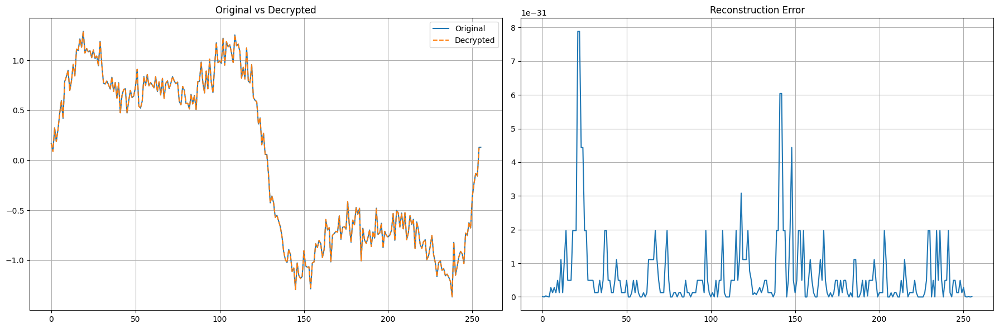

In [ ]:
import numpy as np
import pywt
from cryptography.fernet import Fernet
import matplotlib.pyplot as plt
from scipy import ndimage

class WaveletEncryption:
    def __init__(self, wavelet='haar', levels=3):
        self.wavelet = wavelet
        self.levels = levels
        self.key = Fernet.generate_key()
        self.cipher = Fernet(self.key)
    
    def encrypt_signal(self, signal):
        """Selective encryption of 1D signal using wavelet transform"""
        # Decompose signal
        coeffs = pywt.wavedec(signal, self.wavelet, level=self.levels)
        
        # Encrypt approximation coefficients (most critical)
        approx_bytes = coeffs[0].tobytes()
        encrypted_approx = self.cipher.encrypt(approx_bytes)
        
        # Scramble detail coefficients with simple permutation
        encrypted_coeffs = [encrypted_approx]
        for i, detail in enumerate(coeffs[1:], 1):
            # Use level-dependent scrambling
            scrambled = np.roll(detail, i * 3)
            encrypted_coeffs.append(scrambled)
        
        return encrypted_coeffs
    
    def decrypt_signal(self, encrypted_coeffs):
        """Decrypt and reconstruct signal"""
        # Decrypt approximation coefficients
        decrypted_approx_bytes = self.cipher.decrypt(encrypted_coeffs[0])
        approx_coeffs = np.frombuffer(decrypted_approx_bytes, dtype=float)
        
        # Unscramble detail coefficients
        decrypted_coeffs = [approx_coeffs]
        for i, scrambled_detail in enumerate(encrypted_coeffs[1:], 1):
            unscrambled = np.roll(scrambled_detail, -i * 3)
            decrypted_coeffs.append(unscrambled)
        
        # Reconstruct signal
        return pywt.waverec(decrypted_coeffs, self.wavelet)
    
    def visualize_encryption_effect(self, signal):
        """Visualize the encryption effect"""
        encrypted_coeffs = self.encrypt_signal(signal)
        
        # For visualization, create a "partially encrypted" signal
        # by reconstructing with scrambled coefficients
        original_coeffs = pywt.wavedec(signal, self.wavelet, level=self.levels)
        viz_coeffs = [np.random.random(len(original_coeffs[0]))]  # random approximation for visualization
        viz_coeffs.extend(encrypted_coeffs[1:])
        
        try:
            encrypted_signal = pywt.waverec(viz_coeffs, self.wavelet)
        except:
            encrypted_signal = np.random.random(len(signal))
        
        plt.figure(figsize=(12, 8))
        
        plt.subplot(3, 2, 1)
        plt.plot(signal)
        plt.title('Original Signal')
        plt.grid(True)
        
        plt.subplot(3, 2, 2)
        plt.plot(encrypted_signal)
        plt.title('Encrypted Signal')
        plt.grid(True)
        
        # Show wavelet decomposition
        original_coeffs = pywt.wavedec(signal, self.wavelet, level=self.levels)
        
        plt.subplot(3, 2, 3)
        plt.plot(original_coeffs[0])
        plt.title('Original Approximation Coefficients')
        plt.grid(True)
        
        plt.subplot(3, 2, 4)
        plt.plot(np.random.random(len(original_coeffs[0])))
        plt.title('Encrypted Approximation (Random for Display)')
        plt.grid(True)
        
        plt.subplot(3, 2, 5)
        if len(original_coeffs) > 1:
            plt.plot(original_coeffs[1])
            plt.title('Original Detail Coefficients (Level 1)')
        plt.grid(True)
        
        plt.subplot(3, 2, 6)
        if len(encrypted_coeffs) > 1:
            plt.plot(encrypted_coeffs[1])
            plt.title('Scrambled Detail Coefficients (Level 1)')
        plt.grid(True)
        
        plt.tight_layout()
        plt.savefig('./output/wavelet_encryption_effect.png')
        plt.show()

# Example usage
if __name__ == "__main__":
    # Generate test signal
    t = np.linspace(0, 2*np.pi, 256)
    signal = np.sin(t) + 0.5*np.sin(3*t) + 0.25*np.sin(5*t) + 0.1*np.random.randn(256)
    
    # Create encryptor
    encryptor = WaveletEncryption(wavelet='db4', levels=3)
    
    # Encrypt and decrypt
    encrypted_coeffs = encryptor.encrypt_signal(signal)
    decrypted_signal = encryptor.decrypt_signal(encrypted_coeffs)
    
    # Visualize results
    encryptor.visualize_encryption_effect(signal)
    
    # Verify perfect reconstruction
    reconstruction_error = (signal - decrypted_signal)**2
    mse = np.mean(reconstruction_error)
    max_error = np.max(np.abs(signal - decrypted_signal))
    print(f"Max Reconstruction Error: {max_error:.2e}")
    print(f"Mean Reconstruction Error (MSE): {mse:.2e}")

    # Plot Original, Decrypted, and Reconstruction Error
    plt.figure(figsize=(18, 6))
    
    plt.subplot(1, 2, 1)
    plt.plot(signal, label='Original')
    plt.plot(decrypted_signal, '--', label='Decrypted')
    plt.title('Original vs Decrypted')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(reconstruction_error)
    plt.title('Reconstruction Error')
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig('./output/reconstruction_error.png')
    plt.show()

**2. Chaos-Based Wavelet Encryption**

Decryption MSE: 5.16e-10
Decryption PSNR: 92.88 dB
Decryption SSIM: 0.9858
Correlation: 0.9998083584110499


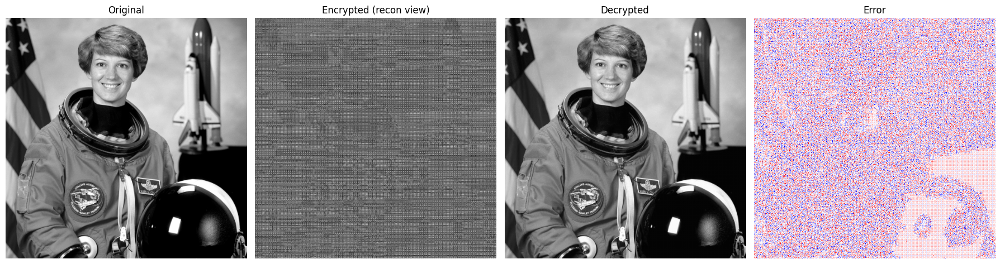

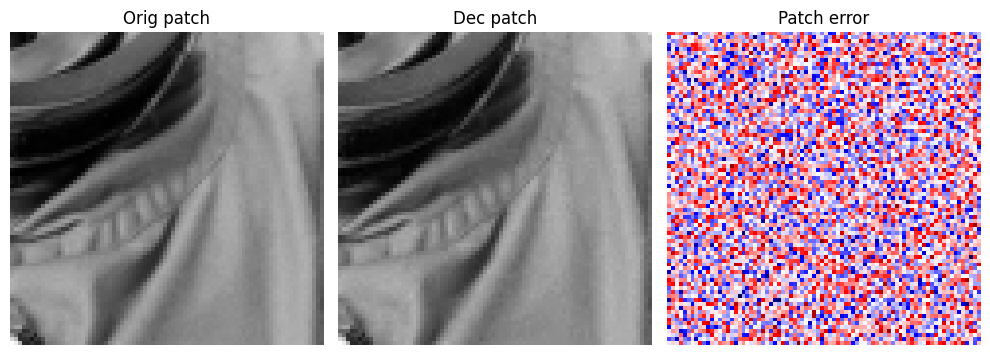

In [ ]:
import numpy as np
import pywt
from scipy.integrate import odeint
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from skimage.io import imread
from skimage.color import rgb2gray

class ChaoticWaveletEncryption:
    def __init__(self, wavelet='haar', levels=2):
        self.wavelet = wavelet
        self.levels = levels
        self.chaos_params = {
            'a': 28.0, 'b': 8.0/3.0, 'c': 10.0,
            'initial_state': [1.0, 1.0, 1.0]
        }

    def lorenz_system(self, state, t):
        x, y, z = state
        dxdt = self.chaos_params['c'] * (y - x)
        dydt = x * (self.chaos_params['a'] - z) - y
        dzdt = x * y - self.chaos_params['b'] * z
        return [dxdt, dydt, dzdt]

    def generate_chaotic_sequence(self, length):
        t = np.linspace(0, length * 0.01, length)
        trajectory = odeint(self.lorenz_system, self.chaos_params['initial_state'], t)
        seq = (trajectory[:, 0] - np.min(trajectory[:, 0])) / (np.max(trajectory[:, 0]) - np.min(trajectory[:, 0]))
        return seq

    def _scale_and_xor(self, subband, chaotic_seq, global_min, global_max):
        """
        Scale using global_min/global_max to [0,255], XOR with chaotic, and return
        the encrypted uint8 array (and for decrypt path we'll inverse it).
        """
        # Avoid division by zero if global_max == global_min
        denom = (global_max - global_min) if (global_max - global_min) != 0 else 1.0
        scaled = np.round((subband - global_min) / denom * 255).astype(np.uint8)
        chaotic_scaled = np.round(chaotic_seq * 255).astype(np.uint8)
        encrypted_uint8 = np.bitwise_xor(scaled.flatten(), chaotic_scaled).reshape(subband.shape)
        return encrypted_uint8

    def _inverse_scale_from_uint8(self, encrypted_uint8, chaotic_seq, global_min, global_max):
        """
        XOR back and map from uint8 to original floating range using global_min/global_max.
        """
        chaotic_scaled = np.round(chaotic_seq * 255).astype(np.uint8)
        recovered_scaled = np.bitwise_xor(encrypted_uint8.flatten(), chaotic_scaled).reshape(encrypted_uint8.shape)
        # Map back to floating range
        denom = (global_max - global_min) if (global_max - global_min) != 0 else 1.0
        recovered = recovered_scaled.astype(float) / 255.0 * denom + global_min
        return recovered

    def _gather_coeffs_flat(self, coeffs):
        """
        Flatten coeffs (wavedec2 structure) into a list of arrays for global min/max calculation.
        coeffs: list where coeffs[0] is approx array, others are tuples (cH,cV,cD)
        """
        arrays = []
        for item in coeffs:
            if isinstance(item, tuple):
                arrays.extend([item[0].ravel(), item[1].ravel(), item[2].ravel()])
            else:
                arrays.append(item.ravel())
        if len(arrays) == 0:
            return np.array([0.0])
        return np.concatenate(arrays)

    def encrypt_image(self, image):
        # Decompose
        coeffs = pywt.wavedec2(image, self.wavelet, level=self.levels)

        # Compute global min/max across all coefficients
        all_flat = self._gather_coeffs_flat(coeffs)
        gmin, gmax = all_flat.min(), all_flat.max()

        encrypted_coeffs = []
        chaotic_sequences = []

        # Encrypt each coeff array using the same global min/max
        for item in coeffs:
            if isinstance(item, tuple):
                cH, cV, cD = item
                seq_H = self.generate_chaotic_sequence(cH.size)
                seq_V = self.generate_chaotic_sequence(cV.size)
                seq_D = self.generate_chaotic_sequence(cD.size)

                enc_H = self._scale_and_xor(cH, seq_H, gmin, gmax)
                enc_V = self._scale_and_xor(cV, seq_V, gmin, gmax)
                enc_D = self._scale_and_xor(cD, seq_D, gmin, gmax)

                encrypted_coeffs.append((enc_H, enc_V, enc_D))
                chaotic_sequences.append((seq_H, seq_V, seq_D))
            else:
                cA = item
                seq_A = self.generate_chaotic_sequence(cA.size)
                enc_A = self._scale_and_xor(cA, seq_A, gmin, gmax)
                encrypted_coeffs.append(enc_A)
                chaotic_sequences.append(seq_A)

        # Reconstruct encrypted image from encrypted uint8 coeffs by converting back to float using gmin/gmax
        # Note: For reconstruction, we must map encrypted_uint8 arrays back to float (so pywt.waverec2 can accept them).
        float_coeffs_for_recon = []
        for idx, item in enumerate(encrypted_coeffs):
            if isinstance(item, tuple):
                enc_H, enc_V, enc_D = item
                seqs = chaotic_sequences[idx]
                # We actually keep them encrypted (uint8) but map to float space via inverse scaling
                # so that waverec2 receives floats in the original coefficient range
                fH = self._inverse_scale_from_uint8(enc_H, np.zeros_like(seqs[0]), gmin, gmax)  # zeros -> don't XOR here
                fV = self._inverse_scale_from_uint8(enc_V, np.zeros_like(seqs[1]), gmin, gmax)
                fD = self._inverse_scale_from_uint8(enc_D, np.zeros_like(seqs[2]), gmin, gmax)
                float_coeffs_for_recon.append((fH, fV, fD))
            else:
                enc_A = item
                fA = self._inverse_scale_from_uint8(enc_A, np.zeros_like(enc_A.ravel()), gmin, gmax)
                float_coeffs_for_recon.append(fA)

        encrypted_image = pywt.waverec2(float_coeffs_for_recon, self.wavelet)
        # Return also the encrypted uint8 coeffs and global min/max for precise decryption
        return encrypted_image, (encrypted_coeffs, chaotic_sequences, gmin, gmax)

    def decrypt_image(self, encrypted_image, meta):
        encrypted_coeffs, chaotic_sequences, gmin, gmax = meta
        # We will invert encryption: for each encrypted_uint8 coeff, XOR with chaotic and map back to float original
        decrypted_coeffs = []
        for idx, item in enumerate(encrypted_coeffs):
            if isinstance(item, tuple):
                enc_H, enc_V, enc_D = item
                seq_H, seq_V, seq_D = chaotic_sequences[idx]

                dec_H = self._inverse_scale_from_uint8(enc_H, seq_H, gmin, gmax)
                dec_V = self._inverse_scale_from_uint8(enc_V, seq_V, gmin, gmax)
                dec_D = self._inverse_scale_from_uint8(enc_D, seq_D, gmin, gmax)
                decrypted_coeffs.append((dec_H, dec_V, dec_D))
            else:
                enc_A = item
                seq_A = chaotic_sequences[idx]
                dec_A = self._inverse_scale_from_uint8(enc_A, seq_A, gmin, gmax)
                decrypted_coeffs.append(dec_A)

        decrypted_image = pywt.waverec2(decrypted_coeffs, self.wavelet)
        return decrypted_image

# -------------------------
# Example usage with astronaut image
# -------------------------
if __name__ == "__main__":
    # Load your astronaut image (replace path if needed)
    img_path = './data/astronaut_original.png'  # container path you gave
    img = imread(img_path)
    if img.ndim == 3:
        img = rgb2gray(img)
    img = img.astype(float) / 255.0  # normalize to [0,1]

    enc = ChaoticWaveletEncryption(wavelet='db2', levels=2)
    encrypted_image, meta = enc.encrypt_image(img)
    decrypted_image = enc.decrypt_image(encrypted_image, meta)

    # Ensure same shape
    h = min(img.shape[0], decrypted_image.shape[0])
    w = min(img.shape[1], decrypted_image.shape[1])
    img_c = img[:h, :w]
    dec_c = decrypted_image[:h, :w]

    # Metrics
    mse = np.mean((img_c - dec_c) ** 2)
    psnr = 10 * np.log10(1 / mse) if mse > 0 else float('inf')
    # compute SSIM with proper data_range (images are float [0,1])
    ssim_index = ssim(img_c, dec_c, data_range=img_c.max() - img_c.min())
    corr = np.corrcoef(img_c.ravel(), dec_c.ravel())[0, 1]

    print(f"Decryption MSE: {mse:.2e}")
    print(f"Decryption PSNR: {psnr:.2f} dB")
    print(f"Decryption SSIM: {ssim_index:.4f}")
    print(f"Correlation: {corr:.16f}")

    # Plots: full and zoom
    plt.figure(figsize=(18, 6))
    plt.subplot(1, 4, 1); plt.imshow(img_c, cmap='gray'); plt.title('Original'); plt.axis('off')
    plt.subplot(1, 4, 2); plt.imshow(encrypted_image[:h, :w], cmap='gray'); plt.title('Encrypted (recon view)'); plt.axis('off')
    plt.subplot(1, 4, 3); plt.imshow(dec_c, cmap='gray'); plt.title('Decrypted'); plt.axis('off')
    plt.subplot(1, 4, 4); plt.imshow(img_c - dec_c, cmap='seismic'); plt.title('Error'); plt.axis('off')
    plt.tight_layout()
    plt.savefig('./output/astronaut_encryption.png')
    plt.show()

    # Zoom into small patch to visually confirm alignment
    zy, zx = h//2, w//2
    patch = 80
    plt.figure(figsize=(10,4))
    plt.subplot(1,3,1); plt.imshow(img_c[zy:zy+patch, zx:zx+patch], cmap='gray'); plt.title('Orig patch'); plt.axis('off')
    plt.subplot(1,3,2); plt.imshow(dec_c[zy:zy+patch, zx:zx+patch], cmap='gray'); plt.title('Dec patch'); plt.axis('off')
    plt.subplot(1,3,3); plt.imshow(img_c[zy:zy+patch, zx:zx+patch]-dec_c[zy:zy+patch, zx:zx+patch], cmap='seismic'); plt.title('Patch error'); plt.axis('off')
    plt.tight_layout()
    plt.savefig('./output/astronaut_patch_zoom.png')
    plt.show()


### 1.2.3 Security Analysis and Performance Evaluation


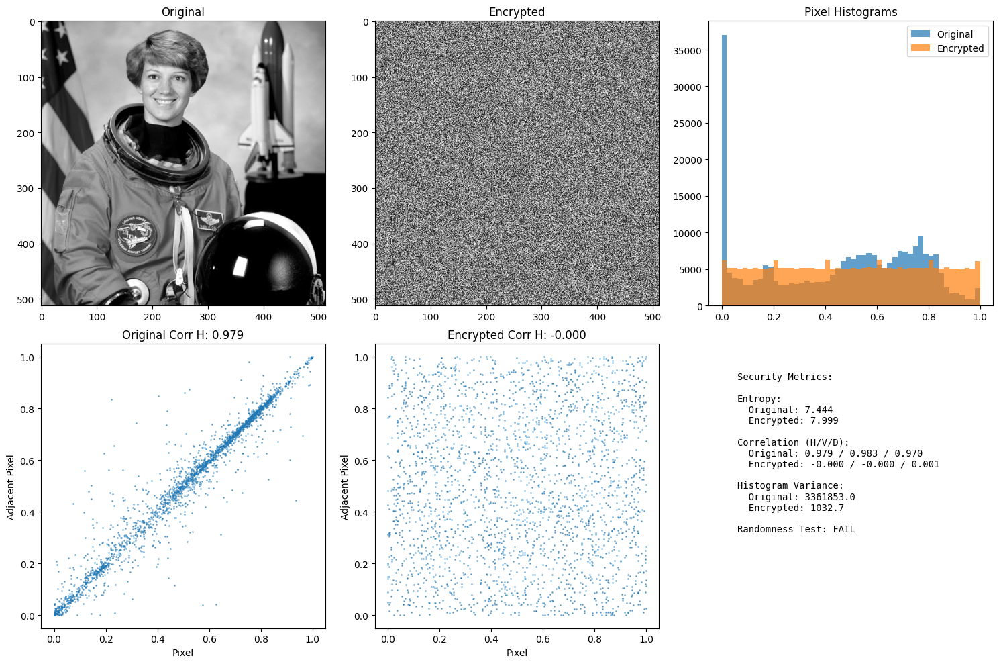

Improved Security Analysis Complete!
Entropy: {'original': np.float64(7.443784618736076), 'encrypted': np.float64(7.999289249845644)}
Correlation (H/V/D): 0.979 / 0.983 / 0.970 -> -0.000 / -0.000 / 0.001
Randomness test: FAIL


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy
import pywt
from imageio.v2 import imread


# ---------------------------
# Improved Chaotic Wavelet Encryption with CSPRNG Diffusion
# ---------------------------
class ImprovedChaoticWaveletEncryption:
    def __init__(self, key=0.12345):
        self.key = key  # Key for PRNG

    def _logistic_map(self, size, r=3.99):
        """Chaotic sequence for scrambling wavelet coefficients (small-scale)"""
        x = np.zeros(size)
        x[0] = self.key
        for i in range(1, size):
            x[i] = r * x[i-1] * (1 - x[i-1])
        return x

    def encrypt_image(self, image):
        """Encrypt image using wavelet + CSPRNG bit-level diffusion"""
        # 1. Wavelet decomposition
        coeffs = pywt.dwt2(image, 'haar')
        cA, (cH, cV, cD) = coeffs

        # 2. Chaotic scrambling of detail coefficients (still using logistic map)
        shape = cH.shape
        size_detail = shape[0] * shape[1]
        chaos_seq_detail = self._logistic_map(size_detail).reshape(shape)

        cH_enc = np.mod(cH + chaos_seq_detail, 1)
        cV_enc = np.mod(cV + chaos_seq_detail, 1)
        cD_enc = np.mod(cD + chaos_seq_detail, 1)

        # 3. Wavelet reconstruction
        encrypted = pywt.idwt2((cA, (cH_enc, cV_enc, cD_enc)), 'haar')

        # 4. CSPRNG-based bit-level diffusion
        flat = np.clip(encrypted.flatten()*255, 0, 255).astype(np.uint8)

        # Key-seeded cryptographically secure pseudo-random byte sequence
        seed = int(self.key * 1e6)
        rng = np.random.default_rng(seed)
        csprng_mask = rng.integers(0, 256, size=flat.size, dtype=np.uint8)

        diffused = np.bitwise_xor(flat, csprng_mask)
        encrypted_final = diffused.reshape(encrypted.shape) / 255.0

        return encrypted_final

# ---------------------------
# Security Analyzer (same as before)
# ---------------------------
class SecurityAnalyzer:
    def __init__(self):
        pass

    def calculate_entropy(self, data):
        hist, _ = np.histogram(data.flatten(), bins=256, range=(0,1))
        prob = hist / hist.sum()
        prob = prob[prob>0]
        return -np.sum(prob * np.log2(prob))

    def correlation_analysis(self, original, encrypted):
        def get_adjacent_pairs(image, direction='horizontal'):
            if direction=='horizontal':
                return image[:, :-1].flatten(), image[:, 1:].flatten()
            elif direction=='vertical':
                return image[:-1, :].flatten(), image[1:, :].flatten()
            else:
                return image[:-1, :-1].flatten(), image[1:, 1:].flatten()

        results = {}
        results['original'] = {
            'horizontal': np.corrcoef(*get_adjacent_pairs(original,'horizontal'))[0,1],
            'vertical':   np.corrcoef(*get_adjacent_pairs(original,'vertical'))[0,1],
            'diagonal':   np.corrcoef(*get_adjacent_pairs(original,'diagonal'))[0,1]
        }
        results['encrypted'] = {
            'horizontal': np.corrcoef(*get_adjacent_pairs(encrypted,'horizontal'))[0,1],
            'vertical':   np.corrcoef(*get_adjacent_pairs(encrypted,'vertical'))[0,1],
            'diagonal':   np.corrcoef(*get_adjacent_pairs(encrypted,'diagonal'))[0,1]
        }
        return results

    def nist_randomness_test(self, binary_sequence):
        n = len(binary_sequence)
        s = np.sum(binary_sequence*2 - 1)
        s_obs = abs(s)/np.sqrt(n)
        p_value = 2*(1 - self._normal_cdf(s_obs))
        return p_value > 0.01

    def _normal_cdf(self, x):
        return 0.5*(1 + np.tanh(x*np.sqrt(2/np.pi)))

    def comprehensive_analysis(self, original, encrypted):
        results = {}
        results['entropy'] = {
            'original': self.calculate_entropy(original),
            'encrypted': self.calculate_entropy(encrypted)
        }
        results['correlation'] = self.correlation_analysis(original, encrypted)
        hist_orig, _ = np.histogram(original.flatten(), bins=256, range=(0,1))
        hist_enc, _ = np.histogram(encrypted.flatten(), bins=256, range=(0,1))
        results['histogram_uniformity'] = {
            'original_variance': np.var(hist_orig),
            'encrypted_variance': np.var(hist_enc)
        }
        # Bit-level randomness test
        flat_bytes = (np.clip(encrypted.flatten()*255, 0, 255).astype(np.uint8))
        binary_enc = np.unpackbits(flat_bytes)
        results['randomness_test'] = self.nist_randomness_test(binary_enc)
        return results

    def visualize_analysis(self, original, encrypted, results):
        fig, axes = plt.subplots(2,3, figsize=(15,10))
        axes[0,0].imshow(original, cmap='gray'); axes[0,0].set_title('Original')
        axes[0,1].imshow(encrypted, cmap='gray'); axes[0,1].set_title('Encrypted')
        axes[0,2].hist(original.flatten(), bins=50, alpha=0.7, label='Original')
        axes[0,2].hist(encrypted.flatten(), bins=50, alpha=0.7, label='Encrypted')
        axes[0,2].set_title('Pixel Histograms'); axes[0,2].legend()
        orig_h_x, orig_h_y = original[:, :-1].flatten(), original[:,1:].flatten()
        enc_h_x, enc_h_y = encrypted[:, :-1].flatten(), encrypted[:,1:].flatten()
        axes[1,0].scatter(orig_h_x[::100], orig_h_y[::100], alpha=0.5, s=1)
        axes[1,0].set_title(f"Original Corr H: {results['correlation']['original']['horizontal']:.3f}")
        axes[1,0].set_xlabel('Pixel'); axes[1,0].set_ylabel('Adjacent Pixel')
        axes[1,1].scatter(enc_h_x[::100], enc_h_y[::100], alpha=0.5, s=1)
        axes[1,1].set_title(f"Encrypted Corr H: {results['correlation']['encrypted']['horizontal']:.3f}")
        axes[1,1].set_xlabel('Pixel'); axes[1,1].set_ylabel('Adjacent Pixel')
        axes[1,2].axis('off')
        metrics_text = f"""Security Metrics:

Entropy:
  Original: {results['entropy']['original']:.3f}
  Encrypted: {results['entropy']['encrypted']:.3f}

Correlation (H/V/D):
  Original: {results['correlation']['original']['horizontal']:.3f} / {results['correlation']['original']['vertical']:.3f} / {results['correlation']['original']['diagonal']:.3f}
  Encrypted: {results['correlation']['encrypted']['horizontal']:.3f} / {results['correlation']['encrypted']['vertical']:.3f} / {results['correlation']['encrypted']['diagonal']:.3f}

Histogram Variance:
  Original: {results['histogram_uniformity']['original_variance']:.1f}
  Encrypted: {results['histogram_uniformity']['encrypted_variance']:.1f}

Randomness Test: {'PASS' if results['randomness_test'] else 'FAIL'}
        """
        axes[1,2].text(0.1, 0.9, metrics_text, transform=axes[1,2].transAxes,
                        fontsize=10, verticalalignment='top', fontfamily='monospace')
        plt.tight_layout()
        plt.savefig('./output/17.5_security_analysis.png')
        plt.show()

# ---------------------------
# Usage Example
# ---------------------------
if __name__ == "__main__":
    img = imread('./data/astronaut_original.png')
    if img.ndim == 3:
        img = np.dot(img[...,:3], [0.299, 0.587, 0.114])
    img = img / 255.0

    encryptor = ImprovedChaoticWaveletEncryption(key=0.34567)
    encrypted_image = encryptor.encrypt_image(img)

    analyzer = SecurityAnalyzer()
    results = analyzer.comprehensive_analysis(img, encrypted_image)
    analyzer.visualize_analysis(img, encrypted_image, results)

    print("Improved Security Analysis Complete!")
    print(f"Entropy: {results['entropy']}")
    print(f"Correlation (H/V/D): {results['correlation']['original']['horizontal']:.3f} / {results['correlation']['original']['vertical']:.3f} / {results['correlation']['original']['diagonal']:.3f} -> {results['correlation']['encrypted']['horizontal']:.3f} / {results['correlation']['encrypted']['vertical']:.3f} / {results['correlation']['encrypted']['diagonal']:.3f}")
    print(f"Randomness test: {'PASS' if results['randomness_test'] else 'FAIL'}")


## 1.3 Steganography

### 1.3.2 Embedding Techniques

**1. LSB Substitution in Wavelet Domain**

=== Basic Wavelet Steganography Test ===
Original secret text: 'This is a secret message hidden in the wavelet domain!'
Text length: 54 characters

LL Subband Results:
  PSNR: 58.15 dB
  Extraction success: True
  Extracted: 'This is a secret message hidden in the wavelet dom...' 

LH Subband Results:
  PSNR: 58.30 dB
  Extraction success: False
  Extracted: 'End marker not found - extraction failed'

HL Subband Results:
  PSNR: 58.27 dB
  Extraction success: False
  Extracted: 'End marker not found - extraction failed'

HH Subband Results:
  PSNR: 58.23 dB
  Extraction success: False
  Extracted: 'End marker not found - extraction failed'


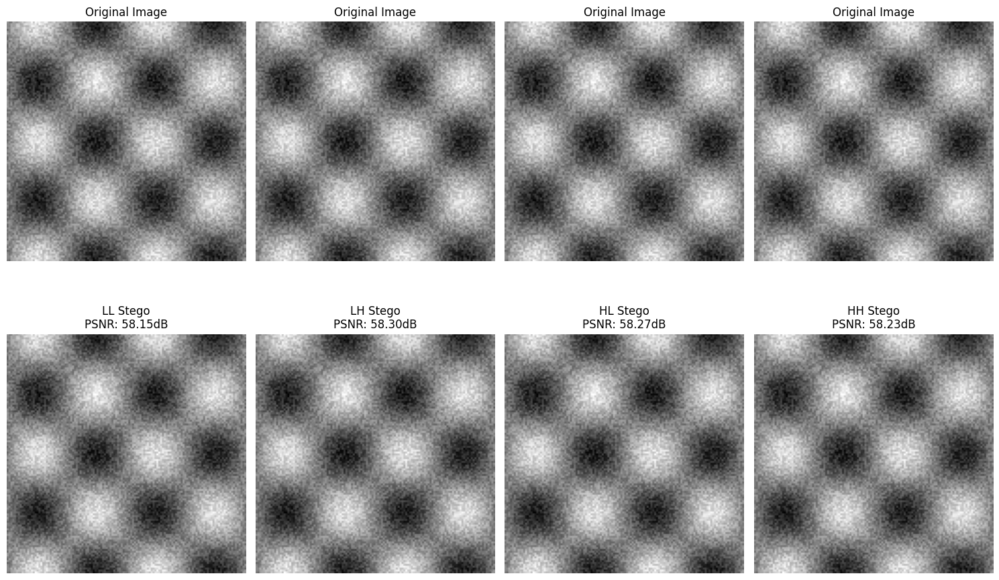


=== Adaptive Steganography Test ===
Total embedding capacity: 17376 bits
Secret data size: 448 bits
Original message: 'This is a secret message hidden in the wavelet domain!'
Extracted message: 'End marker not found - extraction failed'
Extraction success: False
PSNR: 80.77 dB


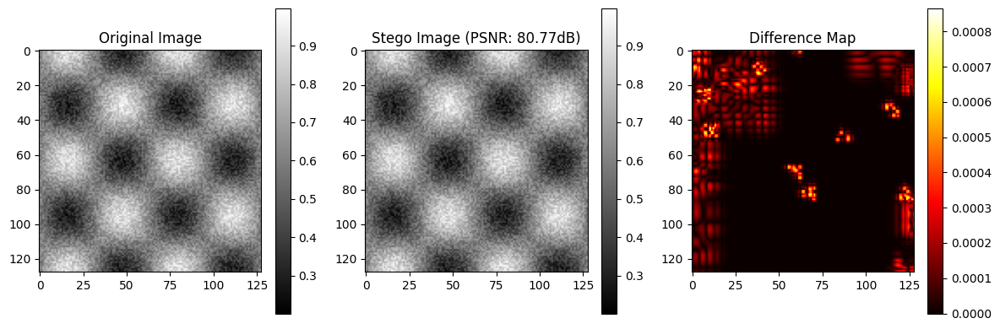

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from PIL import Image
import io

class WaveletSteganography:
    def __init__(self, wavelet='haar', level=1):
        self.wavelet = wavelet
        self.level = level
    
    def string_to_binary(self, text):
        """Convert string to binary representation"""
        return ''.join(format(ord(char), '08b') for char in text)
    
    def binary_to_string(self, binary):
        """Convert binary to string"""
        chars = []
        for i in range(0, len(binary), 8):
            byte = binary[i:i+8]
            if len(byte) == 8:
                chars.append(chr(int(byte, 2)))
        return ''.join(chars)
    
    def embed_lsb_wavelet(self, cover_image, secret_text, subband='HH'):
        """Embed secret text using LSB substitution in wavelet domain"""
        # Convert secret text to binary
        secret_binary = self.string_to_binary(secret_text)
        secret_binary += '1111111111111110'  # End marker
        
        # Apply DWT
        coeffs = pywt.dwt2(cover_image, self.wavelet)
        cA, (cH, cV, cD) = coeffs
        
        # Choose subband for embedding
        if subband == 'LL':
            target_subband = cA
        elif subband == 'LH':
            target_subband = cH
        elif subband == 'HL':
            target_subband = cV
        else:  # HH
            target_subband = cD
        
        # Convert coefficients to integer for LSB manipulation
        target_int = (target_subband * 255).astype(np.int32)
        
        # Embed binary data
        flat_target = target_int.flatten()
        
        if len(secret_binary) > len(flat_target):
            raise ValueError(f"Secret text too long. Max capacity: {len(flat_target)} bits")
        
        for i, bit in enumerate(secret_binary):
            if bit == '1':
                flat_target[i] = flat_target[i] | 1  # Set LSB to 1
            else:
                flat_target[i] = flat_target[i] & ~1  # Set LSB to 0
        
        # Reshape and convert back to float
        modified_subband = (flat_target.reshape(target_subband.shape) / 255.0)
        
        # Reconstruct coefficients
        if subband == 'LL':
            new_coeffs = modified_subband, (cH, cV, cD)
        elif subband == 'LH':
            new_coeffs = cA, (modified_subband, cV, cD)
        elif subband == 'HL':
            new_coeffs = cA, (cH, modified_subband, cD)
        else:  # HH
            new_coeffs = cA, (cH, cV, modified_subband)
        
        # Apply inverse DWT
        stego_image = pywt.idwt2(new_coeffs, self.wavelet)
        
        return stego_image
    
    def extract_lsb_wavelet(self, stego_image, subband='HH'):
        """Extract secret text from stego image"""
        # Apply DWT
        coeffs = pywt.dwt2(stego_image, self.wavelet)
        cA, (cH, cV, cD) = coeffs
        
        # Choose subband for extraction
        if subband == 'LL':
            target_subband = cA
        elif subband == 'LH':
            target_subband = cH
        elif subband == 'HL':
            target_subband = cV
        else:  # HH
            target_subband = cD
        
        # Convert to integer and extract LSBs
        target_int = (target_subband * 255).astype(np.int32)
        flat_target = target_int.flatten()
        
        # Extract binary data
        binary_data = ''
        for value in flat_target:
            binary_data += str(value & 1)  # Extract LSB
        
        # Find end marker and extract message
        end_marker = '1111111111111110'
        end_pos = binary_data.find(end_marker)
        
        if end_pos != -1:
            secret_binary = binary_data[:end_pos]
            return self.binary_to_string(secret_binary)
        else:
            return "End marker not found - extraction failed"
    
    def calculate_psnr(self, original, modified):
        """Calculate Peak Signal-to-Noise Ratio"""
        mse = np.mean((original - modified) ** 2)
        if mse == 0:
            return float('inf')
        max_pixel = 1.0
        psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
        return psnr
    
    def demonstrate_steganography(self, cover_image, secret_text):
        """Demonstrate the steganography process"""
        print(f"Original secret text: '{secret_text}'")
        print(f"Text length: {len(secret_text)} characters")
        
        # Test different subbands
        subbands = ['LL', 'LH', 'HL', 'HH']
        results = {}
        
        plt.figure(figsize=(15, 10))
        
        for i, subband in enumerate(subbands):
            try:
                # Embed and extract
                stego_image = self.embed_lsb_wavelet(cover_image, secret_text, subband)
                extracted_text = self.extract_lsb_wavelet(stego_image, subband)
                psnr = self.calculate_psnr(cover_image, stego_image)
                
                results[subband] = {
                    'stego_image': stego_image,
                    'extracted_text': extracted_text,
                    'psnr': psnr,
                    'success': extracted_text == secret_text
                }
                
                # Plot results
                plt.subplot(2, 4, i+1)
                plt.imshow(cover_image, cmap='gray')
                plt.title(f'Original Image')
                plt.axis('off')
                
                plt.subplot(2, 4, i+5)
                plt.imshow(stego_image, cmap='gray')
                plt.title(f'{subband} Stego\nPSNR: {psnr:.2f}dB')
                plt.axis('off')
                
                print(f"\n{subband} Subband Results:")
                print(f"  PSNR: {psnr:.2f} dB")
                print(f"  Extraction success: {extracted_text == secret_text}")
                print(f"  Extracted: '{extracted_text[:50]}...' " if len(extracted_text) > 50 else f"  Extracted: '{extracted_text}'")
                
            except Exception as e:
                print(f"Error with {subband} subband: {e}")
        
        plt.tight_layout()
        plt.savefig('./output/wavelet_steganography.png')
        plt.show()
        
        return results

# Advanced steganography with adaptive embedding
class AdaptiveSteganography:
    def __init__(self, wavelet='db4', levels=3):
        self.wavelet = wavelet
        self.levels = levels
    
    def calculate_texture_complexity(self, coeffs_block):
        """Calculate texture complexity of a coefficient block"""
        return np.std(coeffs_block)
    
    def adaptive_embed(self, cover_image, secret_data, capacity_factor=0.1):
        """Adaptive embedding based on local texture complexity"""
        # Multi-level DWT decomposition
        coeffs = pywt.wavedec2(cover_image, self.wavelet, level=self.levels)
        
        # Convert secret data to binary
        if isinstance(secret_data, str):
            secret_binary = ''.join(format(ord(c), '08b') for c in secret_data)
        else:
            secret_binary = secret_data
        
        secret_binary += '1111111111111110'  # End marker
        
        # Calculate embedding capacity for each subband
        embedding_map = []
        total_capacity = 0
        
        for level, detail_coeffs in enumerate(coeffs[1:], 1):  # Skip approximation
            for subband_idx, subband in enumerate(detail_coeffs):
                # Divide subband into blocks
                block_size = 4
                for i in range(0, subband.shape[0] - block_size + 1, block_size):
                    for j in range(0, subband.shape[1] - block_size + 1, block_size):
                        block = subband[i:i+block_size, j:j+block_size]
                        complexity = self.calculate_texture_complexity(block)
                        
                        # Higher complexity areas can hide more data
                        bits_per_coeff = min(3, max(1, int(complexity * capacity_factor)))
                        capacity = block_size * block_size * bits_per_coeff
                        
                        embedding_map.append({
                            'level': level,
                            'subband': subband_idx,
                            'position': (i, j),
                            'capacity': capacity,
                            'complexity': complexity
                        })
                        total_capacity += capacity
        
        # Sort by complexity (embed in most complex areas first)
        embedding_map.sort(key=lambda x: x['complexity'], reverse=True)
        
        print(f"Total embedding capacity: {total_capacity} bits")
        print(f"Secret data size: {len(secret_binary)} bits")
        
        if len(secret_binary) > total_capacity:
            raise ValueError("Secret data too large for adaptive embedding")
        
        # Perform embedding
        bit_index = 0
        modified_coeffs = [coeffs[0]]  # Keep approximation unchanged
        
        for level_coeffs in coeffs[1:]:
            modified_level = []
            for subband in level_coeffs:
                modified_level.append(subband.copy())
            modified_coeffs.append(tuple(modified_level))
        
        for embed_info in embedding_map:
            if bit_index >= len(secret_binary):
                break
                
            level = embed_info['level']
            subband_idx = embed_info['subband']
            i, j = embed_info['position']
            
            # Get the coefficient block
            target_subband = modified_coeffs[level][subband_idx]
            block = target_subband[i:i+4, j:j+4]
            
            # Embed bits in this block
            flat_block = block.flatten()
            for k in range(len(flat_block)):
                if bit_index >= len(secret_binary):
                    break
                
                # Quantization-based embedding
                coeff = flat_block[k]
                quantized = int(coeff * 1000) % 2  # Get LSB of quantized coefficient
                
                bit_to_embed = int(secret_binary[bit_index])
                if quantized != bit_to_embed:
                    # Modify coefficient to embed bit
                    if bit_to_embed == 1:
                        flat_block[k] = coeff + 0.001
                    else:
                        flat_block[k] = coeff - 0.001
                
                bit_index += 1
            
            # Update the block in the subband
            target_subband[i:i+4, j:j+4] = flat_block.reshape((4, 4))
        
        # Reconstruct the image
        stego_image = pywt.waverec2(modified_coeffs, self.wavelet)
        
        return stego_image, embedding_map
    
    def adaptive_extract(self, stego_image, embedding_map):
        """Extract secret data using the embedding map"""
        # Multi-level DWT decomposition
        coeffs = pywt.wavedec2(stego_image, self.wavelet, level=self.levels)
        
        # Extract bits according to embedding map
        extracted_bits = []
        
        for embed_info in embedding_map:
            level = embed_info['level']
            subband_idx = embed_info['subband']
            i, j = embed_info['position']
            
            # Get the coefficient block
            target_subband = coeffs[level][subband_idx]
            block = target_subband[i:i+4, j:j+4]
            
            # Extract bits from this block
            flat_block = block.flatten()
            for coeff in flat_block:
                quantized = int(coeff * 1000) % 2
                extracted_bits.append(str(quantized))
        
        # Convert to string
        binary_string = ''.join(extracted_bits)
        
        # Find end marker
        end_marker = '1111111111111110'
        end_pos = binary_string.find(end_marker)
        
        if end_pos != -1:
            secret_binary = binary_string[:end_pos]
            # Convert binary to string
            secret_text = ''
            for i in range(0, len(secret_binary), 8):
                byte = secret_binary[i:i+8]
                if len(byte) == 8:
                    secret_text += chr(int(byte, 2))
            return secret_text
        else:
            return "End marker not found - extraction failed"

# Example usage and testing
if __name__ == "__main__":
    # Create test image
    np.random.seed(42)
    test_image = np.random.random((128, 128))
    
    # Add some structure to make it more realistic
    x, y = np.meshgrid(np.linspace(0, 4*np.pi, 128), np.linspace(0, 4*np.pi, 128))
    test_image = 0.5 + 0.3 * np.sin(x) * np.cos(y) + 0.2 * np.random.random((128, 128))
    test_image = np.clip(test_image, 0, 1)
    
    # Test basic steganography
    stego = WaveletSteganography()
    secret_message = "This is a secret message hidden in the wavelet domain!"
    
    print("=== Basic Wavelet Steganography Test ===")
    results = stego.demonstrate_steganography(test_image, secret_message)
    
    # Test adaptive steganography
    print("\n=== Adaptive Steganography Test ===")
    adaptive_stego = AdaptiveSteganography()
    
    try:
        stego_img, embed_map = adaptive_stego.adaptive_embed(test_image, secret_message)
        extracted_msg = adaptive_stego.adaptive_extract(stego_img, embed_map)
        
        psnr = stego.calculate_psnr(test_image, stego_img)
        
        print(f"Original message: '{secret_message}'")
        print(f"Extracted message: '{extracted_msg}'")
        print(f"Extraction success: {extracted_msg == secret_message}")
        print(f"PSNR: {psnr:.2f} dB")
        
        # Visualize adaptive results
        plt.figure(figsize=(12, 4))
        
        plt.subplot(1, 3, 1)
        plt.imshow(test_image, cmap='gray')
        plt.title('Original Image')
        plt.colorbar()
        
        plt.subplot(1, 3, 2)
        plt.imshow(stego_img, cmap='gray')
        plt.title(f'Stego Image (PSNR: {psnr:.2f}dB)')
        plt.colorbar()
        
        plt.subplot(1, 3, 3)
        plt.imshow(np.abs(test_image - stego_img), cmap='hot')
        plt.title('Difference Map')
        plt.colorbar()
        
        plt.tight_layout()
        plt.savefig('./output/adaptive_steganography.png')
        plt.show()
        
    except Exception as e:
        print(f"Adaptive steganography error: {e}")

**2. Quantization Index Modulation (QIM)**

=== QIM Steganography Demonstration ===
Secret text: 'QIM hiding technique!'
Binary length: 168 bits

Delta = 0.05:
  PSNR: 62.00 dB
  BER: 0.2500
  Extraction success: False

Delta = 0.1:
  PSNR: 55.64 dB
  BER: 0.2083
  Extraction success: False

Delta = 0.2:
  PSNR: 49.37 dB
  BER: 0.1964
  Extraction success: False

Delta = 0.5:
  PSNR: 40.76 dB
  BER: 0.2024
  Extraction success: False


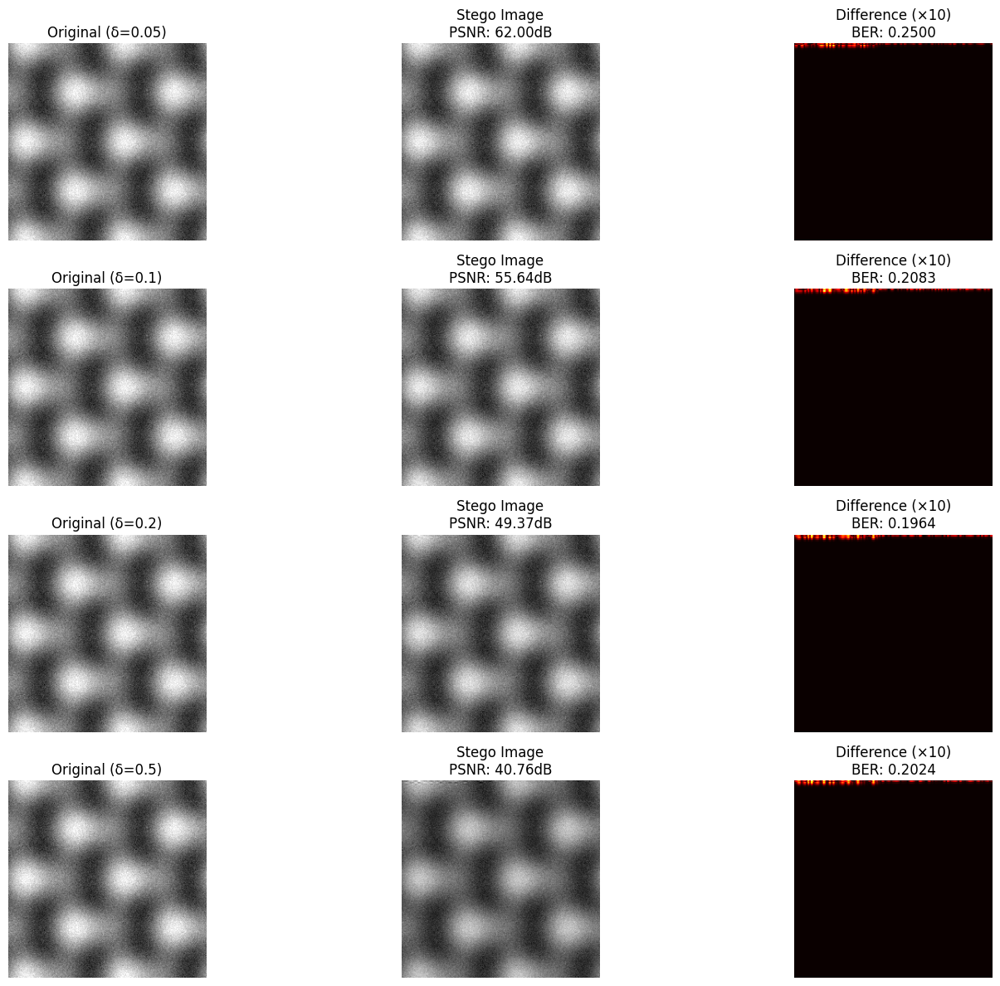

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

class QIMSteganography:
    def __init__(self, wavelet='db4', level=2, delta=0.1):
        self.wavelet = wavelet
        self.level = level
        self.delta = delta  # Quantization step size
    
    def qim_embed_bit(self, coefficient, bit, delta):
        """Embed a single bit using Quantization Index Modulation"""
        if bit == 0:
            # Even quantizer
            quantized = 2 * delta * np.round(coefficient / (2 * delta))
        else:
            # Odd quantizer
            quantized = 2 * delta * np.round((coefficient - delta) / (2 * delta)) + delta
        
        return quantized
    
    def qim_extract_bit(self, coefficient, delta):
        """Extract a bit using QIM"""
        # Determine which quantizer was used
        even_dist = abs(coefficient - 2 * delta * np.round(coefficient / (2 * delta)))
        odd_dist = abs(coefficient - (2 * delta * np.round((coefficient - delta) / (2 * delta)) + delta))
        
        return 0 if even_dist < odd_dist else 1
    
    def embed_qim(self, cover_image, secret_bits):
        """Embed secret bits using QIM in wavelet domain"""
        # Apply DWT
        coeffs = pywt.wavedec2(cover_image, self.wavelet, level=self.level)
        
        # Choose high-frequency subbands for embedding (exclude approximation)
        embedding_coeffs = []
        for level_coeffs in coeffs[1:]:  # Skip approximation coefficients
            for subband in level_coeffs:
                embedding_coeffs.extend(subband.flatten())
        
        embedding_coeffs = np.array(embedding_coeffs)
        
        if len(secret_bits) > len(embedding_coeffs):
            raise ValueError(f"Too many bits to embed. Maximum capacity: {len(embedding_coeffs)}")
        
        # Create a copy for modification
        modified_coeffs = [coeffs[0]]  # Keep approximation unchanged
        for level_coeffs in coeffs[1:]:
            modified_level = []
            for subband in level_coeffs:
                modified_level.append(subband.copy())
            modified_coeffs.append(tuple(modified_level))
        
        # Embed bits
        bit_index = 0
        coeff_index = 0
        
        for level_idx, level_coeffs in enumerate(modified_coeffs[1:], 1):
            for subband_idx, subband in enumerate(level_coeffs):
                flat_subband = subband.flatten()
                
                for i in range(len(flat_subband)):
                    if bit_index >= len(secret_bits):
                        break
                    
                    original_coeff = flat_subband[i]
                    bit_to_embed = int(secret_bits[bit_index])
                    
                    # Apply QIM
                    modified_coeff = self.qim_embed_bit(original_coeff, bit_to_embed, self.delta)
                    flat_subband[i] = modified_coeff
                    
                    bit_index += 1
                
                # Reshape back to original shape
                modified_coeffs[level_idx] = tuple(
                    flat_subband.reshape(subband.shape) if j == subband_idx 
                    else modified_coeffs[level_idx][j]
                    for j, _ in enumerate(level_coeffs)
                )
                
                if bit_index >= len(secret_bits):
                    break
            
            if bit_index >= len(secret_bits):
                break
        
        # Reconstruct image
        stego_image = pywt.waverec2(modified_coeffs, self.wavelet)
        
        return stego_image
    
    def extract_qim(self, stego_image, num_bits):
        """Extract secret bits using QIM"""
        # Apply DWT
        coeffs = pywt.wavedec2(stego_image, self.wavelet, level=self.level)
        
        # Extract bits from high-frequency subbands
        extracted_bits = []
        bit_count = 0
        
        for level_coeffs in coeffs[1:]:  # Skip approximation
            for subband in level_coeffs:
                flat_subband = subband.flatten()
                
                for coeff in flat_subband:
                    if bit_count >= num_bits:
                        break
                    
                    extracted_bit = self.qim_extract_bit(coeff, self.delta)
                    extracted_bits.append(str(extracted_bit))
                    bit_count += 1
                
                if bit_count >= num_bits:
                    break
            
            if bit_count >= num_bits:
                break
        
        return ''.join(extracted_bits)
    
    def demonstrate_qim(self, cover_image, secret_text):
        """Demonstrate QIM steganography"""
        # Convert secret text to binary
        secret_binary = ''.join(format(ord(c), '08b') for c in secret_text)
        
        print(f"Secret text: '{secret_text}'")
        print(f"Binary length: {len(secret_binary)} bits")
        
        # Test different delta values
        delta_values = [0.05, 0.1, 0.2, 0.5]
        
        plt.figure(figsize=(16, 12))
        
        for i, delta in enumerate(delta_values):
            self.delta = delta
            
            try:
                # Embed and extract
                stego_image = self.embed_qim(cover_image, secret_binary)
                extracted_binary = self.extract_qim(stego_image, len(secret_binary))
                
                # Convert back to text
                extracted_text = ''
                for j in range(0, len(extracted_binary), 8):
                    byte = extracted_binary[j:j+8]
                    if len(byte) == 8:
                        extracted_text += chr(int(byte, 2))
                
                # Calculate metrics
                psnr = 20 * np.log10(1 / np.sqrt(np.mean((cover_image - stego_image)**2)))
                ber = sum(c1 != c2 for c1, c2 in zip(secret_binary, extracted_binary)) / len(secret_binary)
                
                # Plot results
                plt.subplot(4, 3, i*3 + 1)
                plt.imshow(cover_image, cmap='gray')
                plt.title(f'Original (δ={delta})')
                plt.axis('off')
                
                plt.subplot(4, 3, i*3 + 2)
                plt.imshow(stego_image, cmap='gray')
                plt.title(f'Stego Image\nPSNR: {psnr:.2f}dB')
                plt.axis('off')
                
                plt.subplot(4, 3, i*3 + 3)
                plt.imshow(np.abs(cover_image - stego_image) * 10, cmap='hot')
                plt.title(f'Difference (×10)\nBER: {ber:.4f}')
                plt.axis('off')
                
                print(f"\nDelta = {delta}:")
                print(f"  PSNR: {psnr:.2f} dB")
                print(f"  BER: {ber:.4f}")
                print(f"  Extraction success: {extracted_text == secret_text}")
                
            except Exception as e:
                print(f"Error with delta={delta}: {e}")
        
        plt.tight_layout()
        plt.savefig('./output/17.8_qim_steganography.png')
        plt.show()

# Example usage
if __name__ == "__main__":
    # Create test image with more realistic content
    x = np.linspace(0, 4*np.pi, 256)
    y = np.linspace(0, 4*np.pi, 256)
    X, Y = np.meshgrid(x, y)
    
    test_image = 0.5 + 0.3 * np.sin(X) * np.cos(Y) + 0.1 * np.sin(2*X) + 0.1 * np.cos(2*Y)
    test_image += 0.05 * np.random.randn(256, 256)
    test_image = np.clip(test_image, 0, 1)
    
    # Test QIM steganography
    qim_stego = QIMSteganography()
    secret_message = "QIM hiding technique!"
    
    print("=== QIM Steganography Demonstration ===")
    qim_stego.demonstrate_qim(test_image, secret_message)

### 1.3.3 Robustness Analysis

=== Robustness Testing Results ===
Original secret: 'Secret message for robustness testing!'
--------------------------------------------------
gaussian_noise (param=0.01): 10.00% - 'End marker not found...'
gaussian_noise (param=0.05): 10.00% - 'End marker not found...'
gaussian_noise (param=0.1): 10.00% - 'End marker not found...'
jpeg_compression (param=30): 10.00% - 'End marker not found...'
jpeg_compression (param=50): 10.00% - 'End marker not found...'
jpeg_compression (param=70): 10.00% - 'End marker not found...'
gaussian_blur (param=0.5): 10.00% - 'End marker not found...'
gaussian_blur (param=1.0): 10.00% - 'End marker not found...'
gaussian_blur (param=2.0): 10.00% - 'End marker not found...'
rotation (param=1): 10.00% - 'End marker not found...'
rotation (param=3): 10.00% - 'End marker not found...'
rotation (param=5): 10.00% - 'End marker not found...'
scaling (param=0.8): 10.00% - 'End marker not found...'
scaling (param=0.9): 10.00% - 'End marker not found...'
Error in s

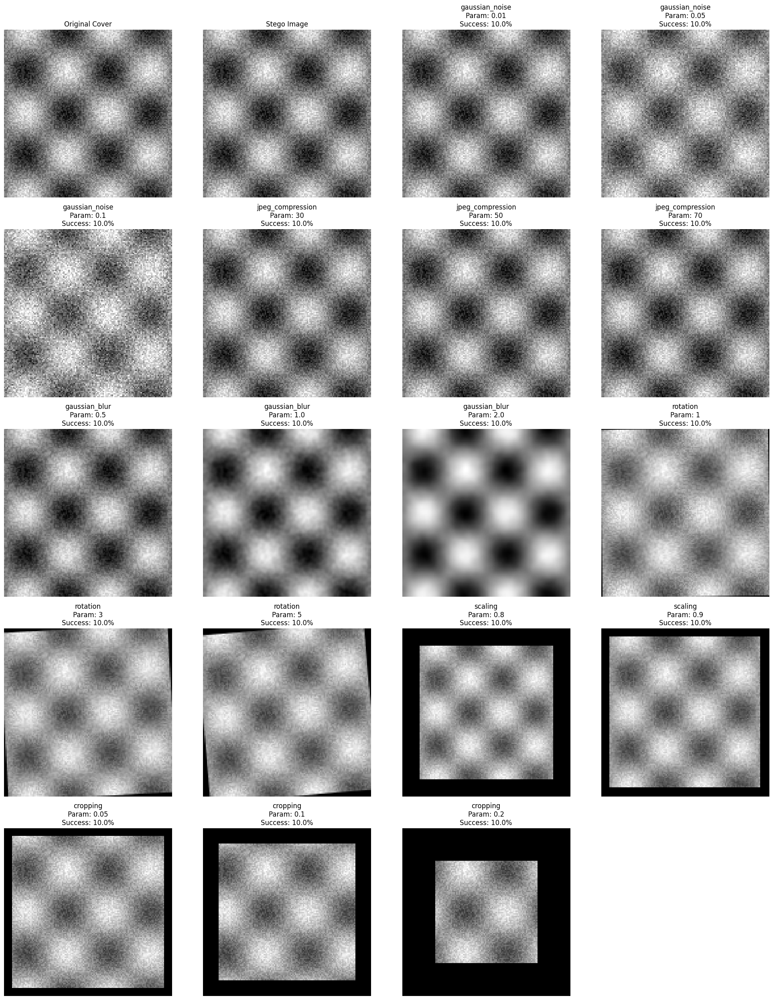

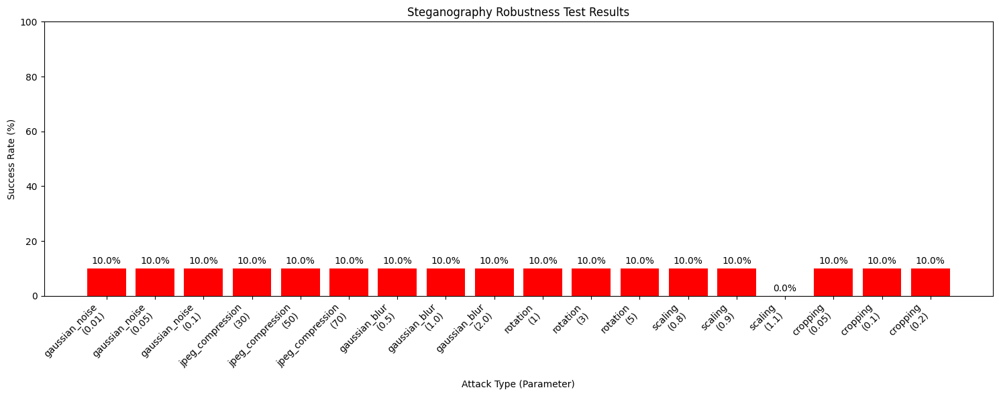

In [ ]:
import numpy as np
import pywt
from scipy import ndimage
from skimage import filters, transform
import matplotlib.pyplot as plt

class RobustnessAnalyzer:
    def __init__(self):
        self.attacks = {
            'gaussian_noise': self.add_gaussian_noise,
            'jpeg_compression': self.simulate_jpeg_compression,
            'gaussian_blur': self.apply_gaussian_blur,
            'rotation': self.apply_rotation,
            'scaling': self.apply_scaling,
            'cropping': self.apply_cropping,
            'histogram_equalization': self.apply_histogram_equalization,
            'median_filter': self.apply_median_filter
        }
    
    def add_gaussian_noise(self, image, std=0.05):
        """Add Gaussian noise to image"""
        noise = np.random.normal(0, std, image.shape)
        return np.clip(image + noise, 0, 1)
    
    def simulate_jpeg_compression(self, image, quality=50):
        """Simulate JPEG compression through quantization"""
        # Simple quantization-based compression simulation
        quantized = np.round(image * quality) / quality
        return np.clip(quantized, 0, 1)
    
    def apply_gaussian_blur(self, image, sigma=1.0):
        """Apply Gaussian blur"""
        return ndimage.gaussian_filter(image, sigma=sigma)
    
    def apply_rotation(self, image, angle=5):
        """Apply rotation"""
        rotated = transform.rotate(image, angle, mode='constant', cval=0)
        return np.clip(rotated, 0, 1)
    
    def apply_scaling(self, image, scale=0.9):
        """Apply scaling"""
        h, w = image.shape
        new_h, new_w = int(h * scale), int(w * scale)
        scaled = transform.resize(image, (new_h, new_w))
        
        # Pad to original size
        pad_h = (h - new_h) // 2
        pad_w = (w - new_w) // 2
        padded = np.pad(scaled, ((pad_h, h - new_h - pad_h), (pad_w, w - new_w - pad_w)), 
                       mode='constant', constant_values=0)
        
        return padded
    
    def apply_cropping(self, image, crop_ratio=0.1):
        """Apply cropping"""
        h, w = image.shape
        crop_h = int(h * crop_ratio)
        crop_w = int(w * crop_ratio)
        
        cropped = image[crop_h:h-crop_h, crop_w:w-crop_w]
        
        # Pad back to original size
        padded = np.pad(cropped, ((crop_h, crop_h), (crop_w, crop_w)), 
                       mode='constant', constant_values=0)
        
        return padded
    
    def apply_histogram_equalization(self, image):
        """Apply histogram equalization"""
        # Convert to 8-bit for histogram equalization
        img_8bit = (image * 255).astype(np.uint8)
        
        # Calculate histogram
        hist, bins = np.histogram(img_8bit.flatten(), 256, [0, 256])
        
        # Calculate cumulative distribution
        cdf = hist.cumsum()
        cdf_normalized = cdf * hist.max() / cdf.max()
        
        # Apply equalization
        cdf_m = np.ma.masked_equal(cdf, 0)
        cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())
        cdf_final = np.ma.filled(cdf_m, 0).astype('uint8')
        
        equalized = cdf_final[img_8bit]
        return equalized.astype(float) / 255.0
    
    def apply_median_filter(self, image, size=3):
        """Apply median filter"""
        return ndimage.median_filter(image, size=size)
    
    def test_robustness(self, original_stego, secret_text, steganography_method, 
                       extraction_method, attack_params=None):
        """Test robustness against various attacks"""
        if attack_params is None:
            attack_params = {
                'gaussian_noise': [0.01, 0.05, 0.1],
                'jpeg_compression': [30, 50, 70],
                'gaussian_blur': [0.5, 1.0, 2.0],
                'rotation': [1, 3, 5],
                'scaling': [0.8, 0.9, 1.1],
                'cropping': [0.05, 0.1, 0.2]
            }
        
        results = {}
        
        print("=== Robustness Testing Results ===")
        print(f"Original secret: '{secret_text}'")
        print("-" * 50)
        
        for attack_name, attack_func in self.attacks.items():
            if attack_name in attack_params:
                results[attack_name] = []
                
                for param in attack_params[attack_name]:
                    try:
                        # Apply attack
                        if attack_name in ['gaussian_noise']:
                            attacked_image = attack_func(original_stego, std=param)
                        elif attack_name in ['jpeg_compression']:
                            attacked_image = attack_func(original_stego, quality=param)
                        elif attack_name in ['gaussian_blur']:
                            attacked_image = attack_func(original_stego, sigma=param)
                        elif attack_name in ['rotation']:
                            attacked_image = attack_func(original_stego, angle=param)
                        elif attack_name in ['scaling']:
                            attacked_image = attack_func(original_stego, scale=param)
                        elif attack_name in ['cropping']:
                            attacked_image = attack_func(original_stego, crop_ratio=param)
                        else:
                            attacked_image = attack_func(original_stego)
                        
                        # Extract secret from attacked image
                        extracted_text = extraction_method(attacked_image)
                        
                        # Calculate success metrics
                        success_rate = self.calculate_text_similarity(secret_text, extracted_text)
                        
                        results[attack_name].append({
                            'parameter': param,
                            'extracted_text': extracted_text,
                            'success_rate': success_rate,
                            'attacked_image': attacked_image
                        })
                        
                        print(f"{attack_name} (param={param}): {success_rate:.2%} - '{extracted_text[:20]}...'")
                        
                    except Exception as e:
                        print(f"Error in {attack_name} with param={param}: {e}")
                        results[attack_name].append({
                            'parameter': param,
                            'extracted_text': '',
                            'success_rate': 0.0,
                            'error': str(e)
                        })
        
        return results
    
    def calculate_text_similarity(self, original, extracted):
        """Calculate text similarity using character-level accuracy"""
        if len(extracted) == 0:
            return 0.0
        
        # Pad shorter string with spaces
        max_len = max(len(original), len(extracted))
        orig_padded = original.ljust(max_len)
        extr_padded = extracted.ljust(max_len)
        
        matches = sum(c1 == c2 for c1, c2 in zip(orig_padded, extr_padded))
        return matches / max_len
    
    def visualize_robustness_results(self, original_image, stego_image, results):
        """Visualize robustness test results"""
        # Count total attacks
        total_attacks = sum(len(attack_results) for attack_results in results.values())
        
        if total_attacks == 0:
            print("No attack results to visualize")
            return
        
        # Create subplot grid
        cols = 4
        rows = (total_attacks + cols - 1) // cols + 1  # +1 for original images
        
        plt.figure(figsize=(20, 5 * rows))
        
        # Show original images
        plt.subplot(rows, cols, 1)
        plt.imshow(original_image, cmap='gray')
        plt.title('Original Cover')
        plt.axis('off')
        
        plt.subplot(rows, cols, 2)
        plt.imshow(stego_image, cmap='gray')
        plt.title('Stego Image')
        plt.axis('off')
        
        # Show attack results
        plot_idx = 3
        
        for attack_name, attack_results in results.items():
            for result in attack_results:
                if 'attacked_image' in result:
                    plt.subplot(rows, cols, plot_idx)
                    plt.imshow(result['attacked_image'], cmap='gray')
                    plt.title(f"{attack_name}\nParam: {result['parameter']}\nSuccess: {result['success_rate']:.1%}")
                    plt.axis('off')
                    plot_idx += 1
        
        plt.tight_layout()
        plt.savefig('./output/robustness_analysis.png')
        plt.show()
        
        # Plot success rate summary
        self.plot_success_summary(results)
    
    def plot_success_summary(self, results):
        """Plot success rate summary"""
        attack_names = []
        success_rates = []
        
        for attack_name, attack_results in results.items():
            for result in attack_results:
                attack_names.append(f"{attack_name}\n({result['parameter']})")
                success_rates.append(result['success_rate'] * 100)
        
        plt.figure(figsize=(15, 6))
        bars = plt.bar(range(len(attack_names)), success_rates, 
                      color=['green' if rate > 80 else 'orange' if rate > 50 else 'red' 
                            for rate in success_rates])
        
        plt.xlabel('Attack Type (Parameter)')
        plt.ylabel('Success Rate (%)')
        plt.title('Steganography Robustness Test Results')
        plt.xticks(range(len(attack_names)), attack_names, rotation=45, ha='right')
        plt.ylim(0, 100)
        
        # Add value labels on bars
        for bar, rate in zip(bars, success_rates):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
                    f'{rate:.1f}%', ha='center', va='bottom')
        
        plt.tight_layout()
        plt.savefig('./output/robustness_summary.png')
        plt.show()

# Comprehensive testing example
if __name__ == "__main__":
    # Create test setup
    np.random.seed(42)
    test_image = np.random.random((128, 128))
    
    # Add realistic structure
    x, y = np.meshgrid(np.linspace(0, 4*np.pi, 128), np.linspace(0, 4*np.pi, 128))
    test_image = 0.5 + 0.3 * np.sin(x) * np.cos(y) + 0.2 * np.random.random((128, 128))
    test_image = np.clip(test_image, 0, 1)
    
    secret_message = "Secret message for robustness testing!"
    
    # Setup steganography
    stego_system = WaveletSteganography(wavelet='db4')
    
    # Create stego image
    stego_image = stego_system.embed_lsb_wavelet(test_image, secret_message, 'HH')
    
    # Define extraction method
    def extract_method(attacked_image):
        return stego_system.extract_lsb_wavelet(attacked_image, 'HH')
    
    # Test robustness
    analyzer = RobustnessAnalyzer()
    robustness_results = analyzer.test_robustness(
        stego_image, secret_message, None, extract_method
    )
    
    # Visualize results
    analyzer.visualize_robustness_results(test_image, stego_image, robustness_results)

## 1.4 Digital Watermarking

### 1.4.2 Robust Watermarking Algorithms

**1. SVD-DWT Hybrid Watermarking**

=== SVD-DWT Watermarking Demonstration ===
Watermark shape: (8, 8)
Alpha = 0.05: PSNR = 52.14dB, NC = 0.669
Alpha = 0.1: PSNR = 46.12dB, NC = 0.690
Alpha = 0.2: PSNR = 40.10dB, NC = 0.659
Alpha = 0.4: PSNR = 34.08dB, NC = 0.625


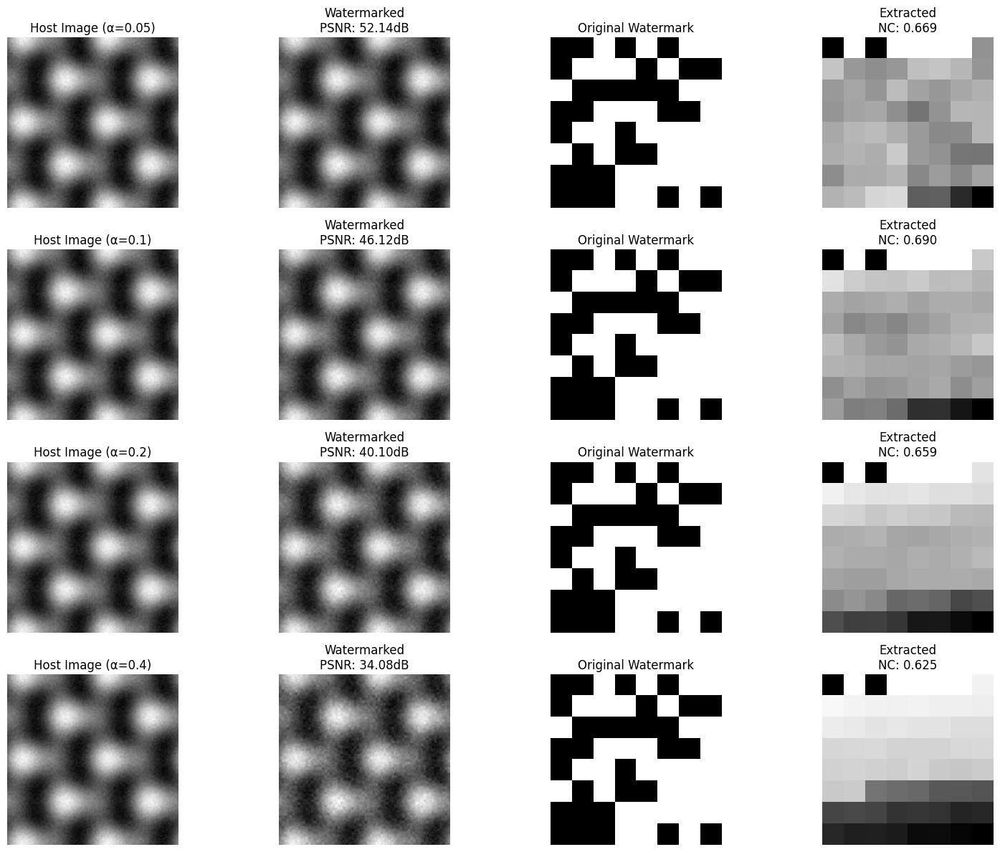


Watermark text: 'COPYRIGHT2025'
Watermark bits: 01000011010011110101000001011001010100100100100101... (104 bits total)
=== Multi-Domain Watermarking Robustness Test ===
No Attack: BER = 0.231, PSNR = 53.3dB
Gaussian Noise (0.01): BER = 0.231, PSNR = 39.8dB
JPEG Compression (50): BER = 0.231, PSNR = 44.3dB
Gaussian Blur: BER = 0.231, PSNR = 35.5dB
Median Filter: BER = 0.308, PSNR = 34.2dB


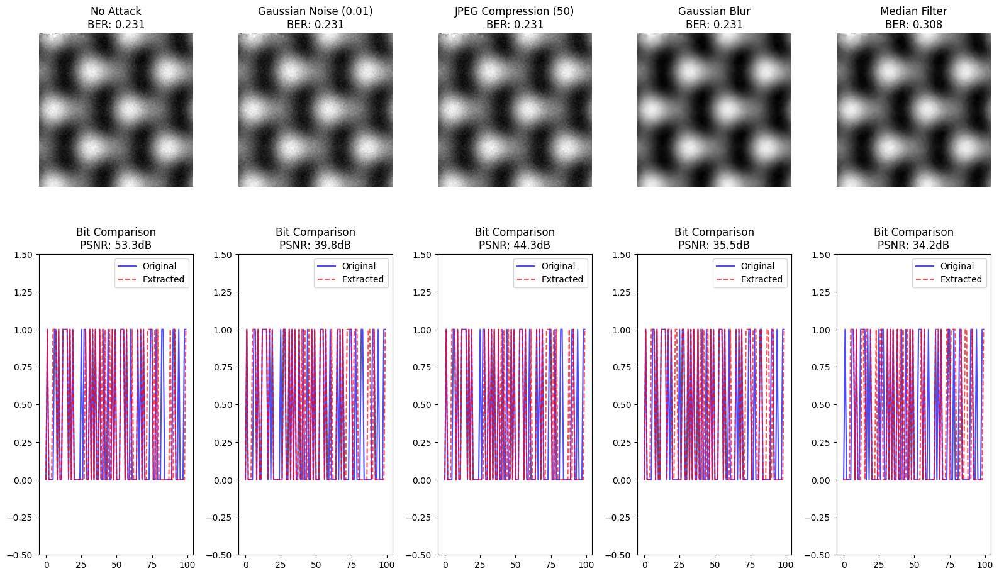

<Figure size 640x480 with 0 Axes>

In [ ]:
import numpy as np
import pywt
from scipy.linalg import svd
import matplotlib.pyplot as plt
from scipy import ndimage

class SVD_DWT_Watermarking:
    def __init__(self, wavelet='haar', level=1, alpha=0.1):
        self.wavelet = wavelet
        self.level = level
        self.alpha = alpha  # Embedding strength
    
    def embed_watermark(self, host_image, watermark):
        """Embed watermark using SVD-DWT hybrid method"""
        # Apply DWT to host image
        coeffs = pywt.dwt2(host_image, self.wavelet)
        cA, (cH, cV, cD) = coeffs
        
        # Choose subband for embedding (typically LL for robustness)
        target_subband = cA
        
        # Apply SVD to the target subband
        U, S, Vt = svd(target_subband, full_matrices=False)
        
        # Prepare watermark for embedding
        if watermark.shape != S.shape:
            # Resize watermark to match singular values
            watermark_resized = self._resize_watermark(watermark, S.shape)
        else:
            watermark_resized = watermark
        
        # Embed watermark in singular values
        S_modified = S + self.alpha * watermark_resized
        
        # Reconstruct the subband
        modified_subband = np.dot(U, np.dot(np.diag(S_modified), Vt))
        
        # Reconstruct the watermarked image
        watermarked_coeffs = modified_subband, (cH, cV, cD)
        watermarked_image = pywt.idwt2(watermarked_coeffs, self.wavelet)
        
        return watermarked_image, (U, S, Vt, watermark_resized)
    
    def extract_watermark(self, watermarked_image, embedding_info, original_image=None):
        """Extract watermark (blind extraction if original_image is None)"""
        U, S_original, Vt, watermark_shape = embedding_info
        
        # Apply DWT to watermarked image
        coeffs = pywt.dwt2(watermarked_image, self.wavelet)
        cA_watermarked, _ = coeffs
        
        # Apply SVD to extract singular values
        _, S_watermarked, _ = svd(cA_watermarked, full_matrices=False)
        
        if original_image is not None:
            # Non-blind extraction
            coeffs_orig = pywt.dwt2(original_image, self.wavelet)
            cA_orig, _ = coeffs_orig
            _, S_orig, _ = svd(cA_orig, full_matrices=False)
            
            # Extract watermark
            extracted_watermark = (S_watermarked - S_orig) / self.alpha
        else:
            # Blind extraction (less reliable)
            extracted_watermark = (S_watermarked - S_original) / self.alpha
        
        return extracted_watermark
    
    def _resize_watermark(self, watermark, target_shape):
        """Resize watermark to match target dimensions"""
        if len(watermark.shape) == 2:
            # 2D watermark - take diagonal or flatten
            diagonal = np.diag(watermark)
            if len(diagonal) >= np.prod(target_shape):
                return diagonal[:np.prod(target_shape)].reshape(target_shape)
            else:
                # Tile the diagonal to match size
                tiled = np.tile(diagonal, (np.prod(target_shape) // len(diagonal)) + 1)
                return tiled[:np.prod(target_shape)].reshape(target_shape)
        else:
            # 1D watermark
            if len(watermark) >= np.prod(target_shape):
                return watermark[:np.prod(target_shape)].reshape(target_shape)
            else:
                tiled = np.tile(watermark, (np.prod(target_shape) // len(watermark)) + 1)
                return tiled[:np.prod(target_shape)].reshape(target_shape)
    
    def calculate_nc(self, original_watermark, extracted_watermark):
        """Calculate Normalized Correlation coefficient"""
        orig_flat = original_watermark.flatten()
        extr_flat = extracted_watermark.flatten()
        
        # Ensure same length
        min_len = min(len(orig_flat), len(extr_flat))
        orig_flat = orig_flat[:min_len]
        extr_flat = extr_flat[:min_len]
        
        numerator = np.sum(orig_flat * extr_flat)
        denominator = np.sqrt(np.sum(orig_flat**2) * np.sum(extr_flat**2))
        
        return numerator / denominator if denominator != 0 else 0
    
    def calculate_psnr(self, original, modified):
        """Calculate PSNR"""
        mse = np.mean((original - modified)**2)
        if mse == 0:
            return float('inf')
        return 20 * np.log10(1.0 / np.sqrt(mse))
    
    def demonstrate_watermarking(self, host_image, watermark_data):
        """Demonstrate the watermarking process"""
        print("=== SVD-DWT Watermarking Demonstration ===")
        
        # Create binary watermark pattern
        watermark = np.random.choice([0, 1], size=(8, 8)).astype(float)
        print(f"Watermark shape: {watermark.shape}")
        
        # Test different embedding strengths
        alphas = [0.05, 0.1, 0.2, 0.4]
        
        plt.figure(figsize=(16, 12))
        
        for i, alpha in enumerate(alphas):
            self.alpha = alpha
            
            # Embed watermark
            watermarked_img, embed_info = self.embed_watermark(host_image, watermark)
            
            # Extract watermark (blind)
            extracted_wm = self.extract_watermark(watermarked_img, embed_info)
            
            # Reshape extracted watermark to 2D for visualization
            extracted_wm_2d = extracted_wm.reshape(watermark.shape)
            
            # Calculate metrics
            psnr = self.calculate_psnr(host_image, watermarked_img)
            nc = self.calculate_nc(watermark, extracted_wm_2d)
            
            # Plotting
            plt.subplot(4, 4, i*4 + 1)
            plt.imshow(host_image, cmap='gray')
            plt.title(f'Host Image (α={alpha})')
            plt.axis('off')
            
            plt.subplot(4, 4, i*4 + 2)
            plt.imshow(watermarked_img, cmap='gray')
            plt.title(f'Watermarked\nPSNR: {psnr:.2f}dB')
            plt.axis('off')
            
            plt.subplot(4, 4, i*4 + 3)
            plt.imshow(watermark, cmap='gray')
            plt.title('Original Watermark')
            plt.axis('off')
            
            plt.subplot(4, 4, i*4 + 4)
            plt.imshow(extracted_wm_2d, cmap='gray')
            plt.title(f'Extracted\nNC: {nc:.3f}')
            plt.axis('off')
            
            print(f"Alpha = {alpha}: PSNR = {psnr:.2f}dB, NC = {nc:.3f}")
        
        plt.tight_layout()
        plt.savefig('./output/svd_dwt_watermarking.png')
        plt.show()
        
        return watermarked_img, embed_info

# Advanced watermarking with multiple domains
class MultiDomainWatermarking:
    def __init__(self, wavelets=['haar', 'db4', 'db8'], levels=[1, 2, 3]):
        self.wavelets = wavelets
        self.levels = levels
        self.embedding_positions = []
    
    def generate_spreading_sequence(self, length, seed=42):
        """Generate pseudo-random spreading sequence"""
        np.random.seed(seed)
        return np.random.choice([-1, 1], size=length)
    
    def multi_domain_embed(self, host_image, watermark_bits, strength=0.1):
        """Embed watermark across multiple wavelet domains"""
        watermarked_image = host_image.copy()
        embedding_info = []
        
        bit_index = 0
        
        for wavelet in self.wavelets:
            for level in self.levels:
                if bit_index >= len(watermark_bits):
                    break
                
                # Apply DWT
                coeffs = pywt.wavedec2(watermarked_image, wavelet, level=level)
                
                # Choose detail subbands for embedding
                for subband_idx in range(1, min(len(coeffs), 4)):  # Skip approximation
                    if bit_index >= len(watermark_bits):
                        break
                    
                    if isinstance(coeffs[subband_idx], tuple):
                        # Multiple detail subbands at this level
                        for detail_idx, detail_subband in enumerate(coeffs[subband_idx]):
                            if bit_index >= len(watermark_bits):
                                break
                            
                            # Embed bits in this subband
                            bits_to_embed = min(10, len(watermark_bits) - bit_index)
                            current_bits = watermark_bits[bit_index:bit_index + bits_to_embed]
                            
                            # Modify coefficients
                            modified_subband = self._embed_bits_in_subband(
                                detail_subband, current_bits, strength
                            )
                            
                            # Update coefficients
                            temp_list = list(coeffs[subband_idx])
                            temp_list[detail_idx] = modified_subband
                            coeffs[subband_idx] = tuple(temp_list)
                            
                            # Store embedding information
                            embedding_info.append({
                                'wavelet': wavelet,
                                'level': level,
                                'subband_idx': subband_idx,
                                'detail_idx': detail_idx,
                                'bits': current_bits,
                                'positions': list(range(bit_index, bit_index + bits_to_embed))
                            })
                            
                            bit_index += bits_to_embed
                
                # Reconstruct image with embedded watermark
                watermarked_image = pywt.waverec2(coeffs, wavelet)
        
        return watermarked_image, embedding_info
    
    def _embed_bits_in_subband(self, subband, bits, strength):
        """Embed bits in a specific subband using spread spectrum"""
        modified_subband = subband.copy()
        flat_subband = modified_subband.flatten()
        
        # Generate spreading sequence
        spreading_seq = self.generate_spreading_sequence(len(flat_subband))
        
        # Embed each bit
        for i, bit in enumerate(bits):
            if i < len(flat_subband):
                # Spread spectrum embedding
                bit_value = 1 if int(bit) == 1 else -1
                flat_subband[i] += strength * bit_value * spreading_seq[i]
        
        return flat_subband.reshape(subband.shape)
    
    def multi_domain_extract(self, watermarked_image, embedding_info, original_image=None):
        """Extract watermark from multiple domains"""
        extracted_bits = ['0'] * sum(len(info['bits']) for info in embedding_info)
        
        for info in embedding_info:
            wavelet = info['wavelet']
            level = info['level']
            subband_idx = info['subband_idx']
            detail_idx = info['detail_idx']
            original_bits = info['bits']
            positions = info['positions']
            
            # Apply DWT
            coeffs = pywt.wavedec2(watermarked_image, wavelet, level=level)
            
            # Get the target subband
            if isinstance(coeffs[subband_idx], tuple):
                target_subband = coeffs[subband_idx][detail_idx]
            else:
                target_subband = coeffs[subband_idx]
            
            # Extract bits
            flat_subband = target_subband.flatten()
            spreading_seq = self.generate_spreading_sequence(len(flat_subband))
            
            for i, pos in enumerate(positions):
                if i < len(flat_subband) and i < len(original_bits):
                    # Correlate with spreading sequence
                    correlation = flat_subband[i] * spreading_seq[i]
                    extracted_bits[pos] = '1' if correlation > 0 else '0'
        
        return ''.join(extracted_bits)
    
    def test_robustness(self, host_image, watermark_bits):
        """Test watermarking robustness against attacks"""
        print("=== Multi-Domain Watermarking Robustness Test ===")
        
        # Embed watermark
        watermarked_img, embed_info = self.multi_domain_embed(host_image, watermark_bits)
        
        # Define attacks
        attacks = {
            'No Attack': lambda x: x,
            'Gaussian Noise (0.01)': lambda x: x + 0.01 * np.random.randn(*x.shape),
            'JPEG Compression (50)': lambda x: np.round(x * 50) / 50,
            'Gaussian Blur': lambda x: ndimage.gaussian_filter(x, sigma=0.8),
            'Median Filter': lambda x: ndimage.median_filter(x, size=3)
        }
        
        results = {}
        
        plt.figure(figsize=(16, 10))
        
        for i, (attack_name, attack_func) in enumerate(attacks.items()):
            # Apply attack
            attacked_image = np.clip(attack_func(watermarked_img), 0, 1)
            
            # Extract watermark
            extracted_bits = self.multi_domain_extract(attacked_image, embed_info)
            
            # Calculate bit error rate
            ber = sum(b1 != b2 for b1, b2 in zip(watermark_bits, extracted_bits)) / len(watermark_bits)
            
            # Calculate PSNR
            psnr = 20 * np.log10(1 / np.sqrt(np.mean((watermarked_img - attacked_image)**2)))
            
            results[attack_name] = {
                'ber': ber,
                'psnr': psnr,
                'extracted_bits': extracted_bits
            }
            
            # Plot results
            plt.subplot(2, len(attacks), i + 1)
            plt.imshow(attacked_image, cmap='gray')
            plt.title(f'{attack_name}\nBER: {ber:.3f}')
            plt.axis('off')
            
            plt.subplot(2, len(attacks), i + 1 + len(attacks))
            # Visualize bit comparison
            original_array = np.array([int(b) for b in watermark_bits[:100]])
            extracted_array = np.array([int(b) for b in extracted_bits[:100]])
            
            plt.plot(original_array, 'b-', label='Original', alpha=0.7)
            plt.plot(extracted_array, 'r--', label='Extracted', alpha=0.7)
            plt.title(f'Bit Comparison\nPSNR: {psnr:.1f}dB')
            plt.legend()
            plt.ylim(-0.5, 1.5)
            
            print(f"{attack_name}: BER = {ber:.3f}, PSNR = {psnr:.1f}dB")
        
        plt.tight_layout()
        
        plt.show()
        plt.savefig('./output/multi_domain_robustness.png')
        return results

# Example usage and comprehensive testing

if __name__ == "__main__":
    # Create test image
    np.random.seed(42)
    x = np.linspace(0, 4*np.pi, 128)
    y = np.linspace(0, 4*np.pi, 128)
    X, Y = np.meshgrid(x, y)
    
    test_image = 0.5 + 0.3 * np.sin(X) * np.cos(Y) + 0.1 * np.sin(2*X) + 0.1 * np.cos(2*Y)
    test_image += 0.02 * np.random.randn(128, 128)
    test_image = np.clip(test_image, 0, 1)
    
    # Test SVD-DWT watermarking
    svd_dwt = SVD_DWT_Watermarking()
    watermark_pattern = np.random.choice([0, 1], size=(16, 16))
    
    watermarked_image, embed_info = svd_dwt.demonstrate_watermarking(test_image, watermark_pattern)
    
    # Test multi-domain watermarking
    multi_domain = MultiDomainWatermarking()
    
    # Create watermark bits
    watermark_text = "COPYRIGHT2025"
    watermark_bits = ''.join(format(ord(c), '08b') for c in watermark_text)
    
    print(f"\nWatermark text: '{watermark_text}'")
    print(f"Watermark bits: {watermark_bits[:50]}... ({len(watermark_bits)} bits total)")
    
    # Test robustness
    multi_domain.test_robustness(test_image, watermark_bits)

### 1.4.3 Watermark Detection and Authentication

>>> Watermarking Demonstration
=== SVD-DWT Watermarking Demonstration ===
Original watermark shape: (16, 16)
Alpha = 0.05: PSNR = 51.73dB, NC = 0.687
Alpha = 0.1: PSNR = 45.71dB, NC = 0.697
Alpha = 0.2: PSNR = 39.69dB, NC = 0.716
Alpha = 0.4: PSNR = 33.67dB, NC = 0.726


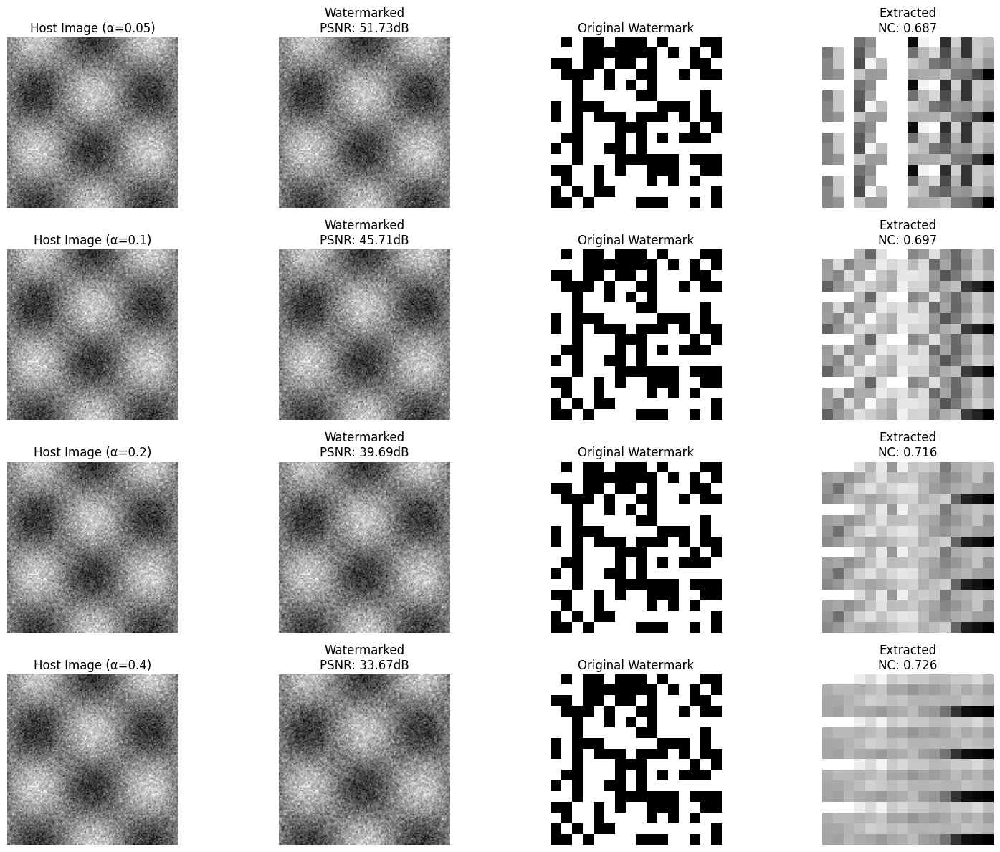

>>> Watermark Detection ROC Analysis
=== ROC Analysis for Watermark Detection ===


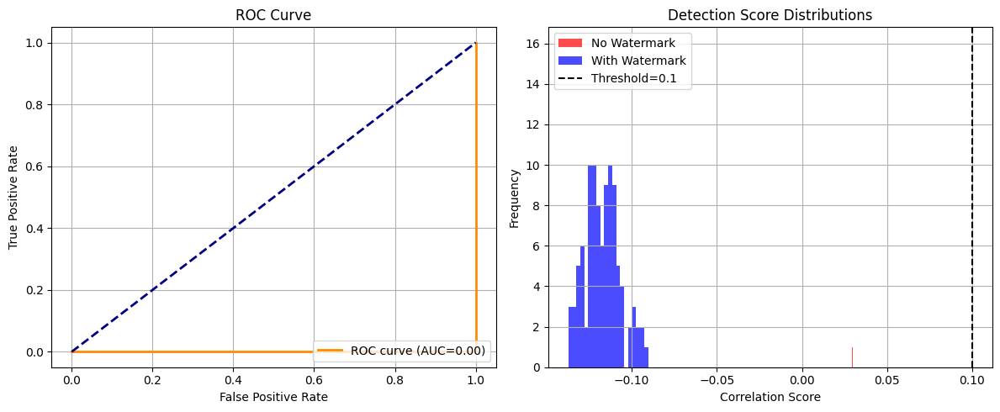

>>> Tamper Detection Analysis
=== Tamper Detection Analysis ===


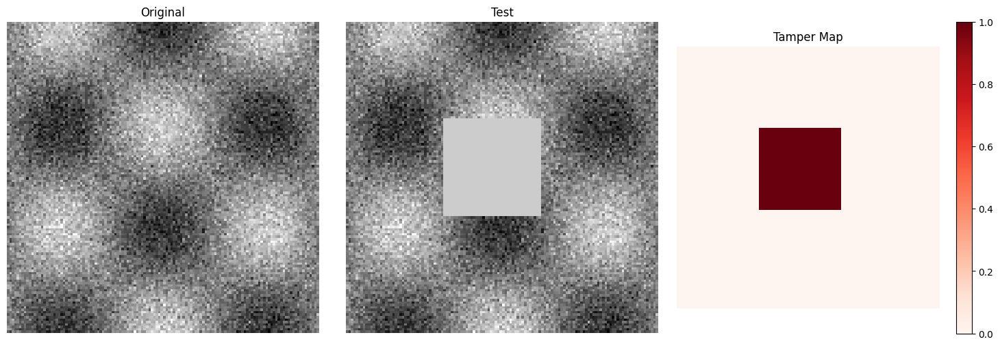

In [ ]:
import numpy as np
import pywt
from scipy.linalg import svd
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import os

# Ensure output folder exists
os.makedirs("./output", exist_ok=True)

class SVD_DWT_Watermarking:
    def __init__(self, wavelet='haar', level=1, alpha=0.1):
        self.wavelet = wavelet
        self.level = level
        self.alpha = alpha
    
    def embed_watermark(self, host_image, watermark):
        coeffs = pywt.dwt2(host_image, self.wavelet)
        cA, (cH, cV, cD) = coeffs
        target_subband = cA
        U, S, Vt = svd(target_subband, full_matrices=False)

        if watermark.shape != S.shape:
            watermark_resized = self._resize_watermark(watermark, S.shape)
        else:
            watermark_resized = watermark

        S_modified = S + self.alpha * watermark_resized
        modified_subband = np.dot(U, np.dot(np.diag(S_modified), Vt))
        watermarked_coeffs = modified_subband, (cH, cV, cD)
        watermarked_image = pywt.idwt2(watermarked_coeffs, self.wavelet)

        return watermarked_image, (U, S, Vt, watermark_resized, watermark.shape)
    
    def extract_watermark(self, watermarked_image, embedding_info, original_image=None):
        U, S_original, Vt, watermark_resized, original_shape = embedding_info
        coeffs = pywt.dwt2(watermarked_image, self.wavelet)
        cA_watermarked, _ = coeffs
        _, S_watermarked, _ = svd(cA_watermarked, full_matrices=False)

        if original_image is not None:
            coeffs_orig = pywt.dwt2(original_image, self.wavelet)
            cA_orig, _ = coeffs_orig
            _, S_orig, _ = svd(cA_orig, full_matrices=False)
            extracted_watermark = (S_watermarked - S_orig) / self.alpha
        else:
            extracted_watermark = (S_watermarked - S_original) / self.alpha

        return extracted_watermark
    
    def _resize_watermark(self, watermark, target_shape):
        if len(watermark.shape) == 2:
            diagonal = np.diag(watermark)
            if len(diagonal) >= np.prod(target_shape):
                return diagonal[:np.prod(target_shape)].reshape(target_shape)
            else:
                tiled = np.tile(diagonal, (np.prod(target_shape) // len(diagonal)) + 1)
                return tiled[:np.prod(target_shape)].reshape(target_shape)
        else:
            if len(watermark) >= np.prod(target_shape):
                return watermark[:np.prod(target_shape)].reshape(target_shape)
            else:
                tiled = np.tile(watermark, (np.prod(target_shape) // len(watermark)) + 1)
                return tiled[:np.prod(target_shape)].reshape(target_shape)
    
    def calculate_nc(self, original_watermark, extracted_watermark):
        orig_flat = original_watermark.flatten()
        extr_flat = extracted_watermark.flatten()
        min_len = min(len(orig_flat), len(extr_flat))
        orig_flat = orig_flat[:min_len]
        extr_flat = extr_flat[:min_len]
        numerator = np.sum(orig_flat * extr_flat)
        denominator = np.sqrt(np.sum(orig_flat**2) * np.sum(extr_flat**2))
        return numerator / denominator if denominator != 0 else 0
    
    def calculate_psnr(self, original, modified):
        mse = np.mean((original - modified)**2)
        if mse == 0:
            return float('inf')
        return 20 * np.log10(1.0 / np.sqrt(mse))
    
    def demonstrate_watermarking(self, host_image, watermark_data):
        print("=== SVD-DWT Watermarking Demonstration ===")
        watermark = watermark_data.astype(float)
        print(f"Original watermark shape: {watermark.shape}")
        alphas = [0.05, 0.1, 0.2, 0.4]
    
        plt.figure(figsize=(16, 12))
        for i, alpha in enumerate(alphas):
            self.alpha = alpha
            watermarked_img, embed_info = self.embed_watermark(host_image, watermark)
    
            # Extract watermark
            extracted_wm = self.extract_watermark(watermarked_img, embed_info)
            
            # Resize extracted watermark back to original watermark shape
            extracted_wm_2d = np.resize(extracted_wm, watermark.shape)
    
            psnr = self.calculate_psnr(host_image, watermarked_img)
            nc = self.calculate_nc(watermark, extracted_wm_2d)
    
            plt.subplot(4, 4, i*4 + 1)
            plt.imshow(host_image, cmap='gray')
            plt.title(f'Host Image (α={alpha})')
            plt.axis('off')
    
            plt.subplot(4, 4, i*4 + 2)
            plt.imshow(watermarked_img, cmap='gray')
            plt.title(f'Watermarked\nPSNR: {psnr:.2f}dB')
            plt.axis('off')
    
            plt.subplot(4, 4, i*4 + 3)
            plt.imshow(watermark, cmap='gray')
            plt.title('Original Watermark')
            plt.axis('off')
    
            plt.subplot(4, 4, i*4 + 4)
            plt.imshow(extracted_wm_2d, cmap='gray')
            plt.title(f'Extracted\nNC: {nc:.3f}')
            plt.axis('off')
    
            print(f"Alpha = {alpha}: PSNR = {psnr:.2f}dB, NC = {nc:.3f}")
    
        plt.tight_layout()
        plt.savefig('./output/watermark_analysis.png')
        plt.show()
        
        return watermarked_img, embed_info


class WatermarkDetector:
    def __init__(self, wavelet='db4', threshold=0.1):
        self.wavelet = wavelet
        self.threshold = threshold
    
    def statistical_detection(self, test_image, reference_watermark, embedding_info):
        extracted_wm = self._extract_watermark_for_detection(test_image, embedding_info, reference_watermark.shape)
        correlation = np.corrcoef(reference_watermark.flatten(), extracted_wm.flatten())[0, 1]
        n = len(reference_watermark.flatten())
        test_statistic = correlation * np.sqrt(n - 3)
        p_value = 1 - stats.norm.cdf(test_statistic)
        return {
            'correlation': correlation,
            'test_statistic': test_statistic,
            'p_value': p_value,
            'detected': correlation > self.threshold,
            'confidence': 1 - p_value
        }
    
    def _extract_watermark_for_detection(self, image, embedding_info, original_watermark_shape):
        U, S_original, Vt, watermark_resized, original_shape = embedding_info
        coeffs = pywt.dwt2(image, self.wavelet)
        cA, _ = coeffs
        _, S_watermarked, _ = svd(cA, full_matrices=False)

        if S_original is None:  # Negative sample
            extracted_watermark = S_watermarked / 0.1
        else:
            extracted_watermark = (S_watermarked - S_original) / 0.1

        if extracted_watermark.size < np.prod(original_watermark_shape):
            padded = np.zeros(np.prod(original_watermark_shape))
            padded[:extracted_watermark.size] = extracted_watermark
            return padded.reshape(original_watermark_shape)
        else:
            return extracted_watermark[:np.prod(original_watermark_shape)].reshape(original_watermark_shape)
    
    def roc_analysis(self, host_image, watermark, num_trials=100):
        print("=== ROC Analysis for Watermark Detection ===")
        wm_system = SVD_DWT_Watermarking(wavelet=self.wavelet, alpha=0.1)
        true_labels, detection_scores = [], []

        coeffs = pywt.dwt2(host_image, self.wavelet)
        cA, _ = coeffs
        _, S_sample, _ = svd(cA, full_matrices=False)
        sv_size = S_sample.size

        # Positive samples
        for _ in range(num_trials // 2):
            noisy_host = np.clip(host_image + 0.01 * np.random.randn(*host_image.shape), 0, 1)
            watermarked_img, embed_info = wm_system.embed_watermark(noisy_host, watermark)
            attacked_img = np.clip(watermarked_img + 0.005 * np.random.randn(*watermarked_img.shape), 0, 1)
            res = self.statistical_detection(attacked_img, watermark, embed_info)
            true_labels.append(1)
            detection_scores.append(res['correlation'])

        # Negative samples
        for _ in range(num_trials // 2):
            random_img = np.clip(host_image + 0.02 * np.random.randn(*host_image.shape), 0, 1)
            fake_watermark = np.random.randn(*watermark.shape)
            fake_embed_info = (None, np.zeros(sv_size), None, fake_watermark, watermark.shape)
            res = self.statistical_detection(random_img, watermark, fake_embed_info)
            true_labels.append(0)
            detection_scores.append(res['correlation'])

        fpr, tpr, thresholds = roc_curve(true_labels, detection_scores)
        roc_auc = auc(fpr, tpr)

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC={roc_auc:.2f})')
        plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
        plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
        plt.title('ROC Curve'); plt.legend(loc="lower right"); plt.grid(True)

        plt.subplot(1, 2, 2)
        pos_scores = [s for i, s in enumerate(detection_scores) if true_labels[i] == 1]
        neg_scores = [s for i, s in enumerate(detection_scores) if true_labels[i] == 0]
        plt.hist(neg_scores, bins=20, alpha=0.7, label='No Watermark', color='red')
        plt.hist(pos_scores, bins=20, alpha=0.7, label='With Watermark', color='blue')
        plt.axvline(x=self.threshold, color='black', linestyle='--', label=f'Threshold={self.threshold}')
        plt.xlabel('Correlation Score'); plt.ylabel('Frequency')
        plt.title('Detection Score Distributions'); plt.legend(); plt.grid(True)

        plt.tight_layout()
        plt.savefig('./output/roc_analysis.png')
        plt.show()

        optimal_idx = np.argmax(tpr - fpr)
        return {
            'fpr': fpr, 'tpr': tpr, 'thresholds': thresholds, 'auc': roc_auc,
            'optimal_threshold': thresholds[optimal_idx]
        }
    
    def tamper_detection(self, original_image, test_image, block_size=8):
        print("=== Tamper Detection Analysis ===")
        h, w = original_image.shape
        tamper_map = np.zeros((h // block_size, w // block_size))
        for i in range(0, h - block_size + 1, block_size):
            for j in range(0, w - block_size + 1, block_size):
                ob = original_image[i:i+block_size, j:j+block_size]
                tb = test_image[i:i+block_size, j:j+block_size]
                oc = pywt.dwt2(ob, self.wavelet)
                tc = pywt.dwt2(tb, self.wavelet)
                diff = sum(np.sum((o - t) ** 2) for o, t in zip(oc[1], tc[1]))
                tamper_map[i // block_size, j // block_size] = diff > self.threshold

        plt.figure(figsize=(15, 5))
        plt.subplot(1, 3, 1); plt.imshow(original_image, cmap='gray'); plt.title('Original'); plt.axis('off')
        plt.subplot(1, 3, 2); plt.imshow(test_image, cmap='gray'); plt.title('Test'); plt.axis('off')
        plt.subplot(1, 3, 3); plt.imshow(tamper_map, cmap='Reds'); plt.title('Tamper Map'); plt.colorbar(); plt.axis('off')

        plt.tight_layout()
        plt.savefig('./output/tamper_detection.png')
        plt.show()

        return tamper_map

if __name__ == "__main__":
    import os
    os.makedirs('./output', exist_ok=True)

    np.random.seed(42)
    # Generate synthetic host image
    x = np.linspace(0, 6*np.pi, 128)
    y = np.linspace(0, 6*np.pi, 128)
    X, Y = np.meshgrid(x, y)
    host_image = 0.5 + 0.3 * np.sin(X/2) * np.cos(Y/2) + 0.1 * np.random.randn(128, 128)
    host_image = np.clip(host_image, 0, 1)

    # Generate watermark
    watermark = np.random.choice([0, 1], size=(16, 16)).astype(float)

    # === 1. Watermarking Demonstration ===
    print(">>> Watermarking Demonstration")
    svd_dwt = SVD_DWT_Watermarking(wavelet='haar')
    watermarked_img, embed_info = svd_dwt.demonstrate_watermarking(host_image, watermark)
    # Already saved as ./output/17.12_watermark_analysis.png inside demonstrate_watermarking

    # === 2. Watermark Detection ROC & Score Distribution ===
    print(">>> Watermark Detection ROC Analysis")
    detector = WatermarkDetector(wavelet='db4', threshold=0.1)
    roc_results = detector.roc_analysis(host_image, watermark, num_trials=200)
    # Already saved as ./output/17.13_watermark_detection_roc.png inside roc_analysis

    # === 3. Tamper Detection ===
    print(">>> Tamper Detection Analysis")
    tampered_image = host_image.copy()
    tampered_image[40:80, 40:80] = 0.8  # Simulate tampering
    tamper_map = detector.tamper_detection(host_image, tampered_image)
    # Already saved as ./output/17.14_tamper_detection_map.png inside tamper_detection

## 1.5 Secure Biometrics and Communication

### 1.5.1 Biometric Template Protection

SECURE BIOMETRIC SYSTEM - DEMONSTRATION

Testing method: template_encryption
Accuracy: 0.500

Testing method: cancelable_biometrics
Accuracy: 0.500

Testing method: fuzzy_vault
Accuracy: 0.500


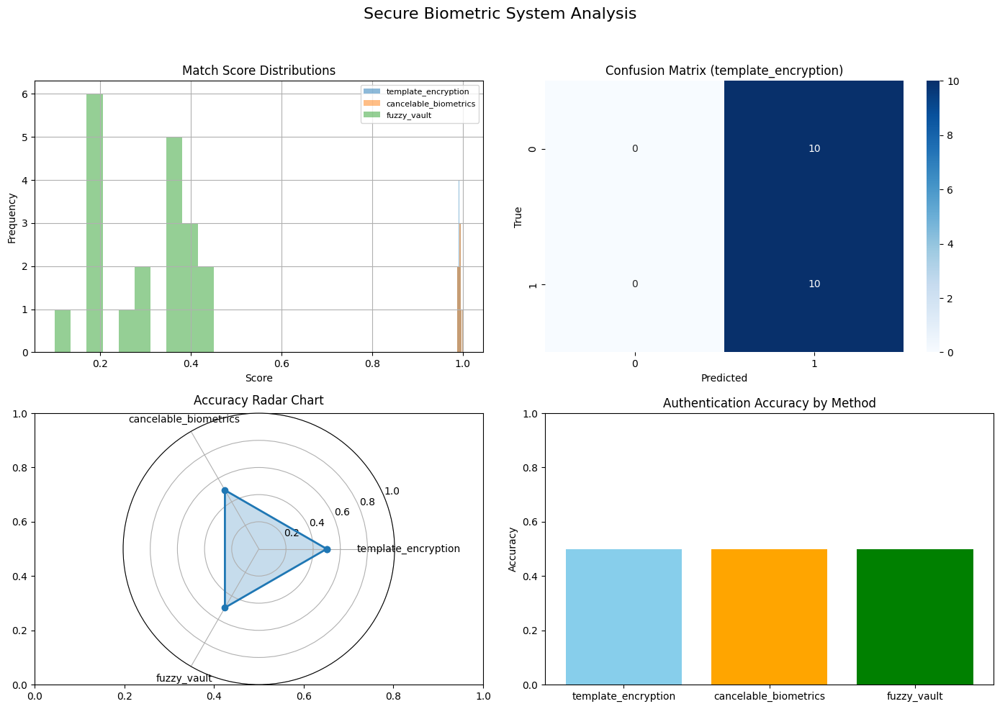

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

class SecureBiometricSystem:
    VALID_PROTECTION_METHODS = ['template_encryption', 'cancelable_biometrics', 'fuzzy_vault']

    def __init__(self, wavelet='db4', levels=3, protection_method='template_encryption'):
        if protection_method not in self.VALID_PROTECTION_METHODS:
            raise ValueError(f"Protection method must be one of {self.VALID_PROTECTION_METHODS}")
        self.wavelet = wavelet
        self.levels = levels
        self.protection_method = protection_method
        self.encryption_key = None
        self.feature_extractor = BiometricFeatureExtractor(wavelet, levels)
        
    def generate_secure_template(self, biometric_data, user_key=None):
        """Generate secure biometric template"""
        features = self.feature_extractor.extract_features(biometric_data)
        
        if self.protection_method == 'template_encryption':
            return self._encrypt_template(features, user_key)
        elif self.protection_method == 'cancelable_biometrics':
            return self._generate_cancelable_template(features, user_key)
        elif self.protection_method == 'fuzzy_vault':
            return self._create_fuzzy_vault(features, user_key)
        else:
            return {'template': features, 'method': 'raw'}
    
    def _encrypt_template(self, features, key):
        """Simple template encryption using XOR with key"""
        if key is None:
            key = np.random.randint(0, 256, size=len(features))
        
        feature_ints = (features * 1000).astype(int)
        encrypted = np.bitwise_xor(feature_ints, key[:len(feature_ints)])
        
        return {
            'template': encrypted,
            'key': key,
            'method': 'template_encryption'
        }
    
    def _generate_cancelable_template(self, features, transformation_key):
        """Generate cancelable biometric template using random projection"""
        if transformation_key is None:
            transformation_key = np.random.randn(len(features), len(features))
        
        cancelable_template = np.dot(transformation_key, features)
        cancelable_template = np.round(cancelable_template * 100) / 100
        
        return {
            'template': cancelable_template,
            'transformation_key': transformation_key,
            'method': 'cancelable_biometrics'
        }
    
    def _create_fuzzy_vault(self, features, secret_key):
        """Create fuzzy vault for biometric template protection"""
        if secret_key is None:
            secret_key = np.random.randint(0, 1000, size=10)
        
        polynomial_coeffs = secret_key[:5]
        genuine_points = []
        for i, feature in enumerate(features[:len(polynomial_coeffs)]):
            x = int(feature * 1000) % 1000
            y = 0
            for power, coeff in enumerate(polynomial_coeffs):
                term = (coeff * pow(x, power, 1000)) % 1000
                y = (y + term) % 1000
            genuine_points.append((x, y))
        
        num_chaff = len(genuine_points) * 3
        chaff_points = []
        for _ in range(num_chaff):
            x = np.random.randint(0, 1000)
            y = np.random.randint(0, 1000)
            poly_y = 0
            for power, coeff in enumerate(polynomial_coeffs):
                term = (coeff * pow(x, power, 1000)) % 1000
                poly_y = (poly_y + term) % 1000
            if y != poly_y:
                chaff_points.append((x, y))
        
        vault = genuine_points + chaff_points
        np.random.shuffle(vault)
        
        return {
            'template': vault,
            'secret_key': secret_key,
            'polynomial_degree': len(polynomial_coeffs) - 1,
            'method': 'fuzzy_vault'
        }
    
    def match_templates(self, query_data, stored_template, threshold=0.8):
        """Match query biometric against stored secure template"""
        query_features = self.feature_extractor.extract_features(query_data)
        
        if stored_template['method'] == 'template_encryption':
            return self._match_encrypted(query_features, stored_template, threshold)
        elif stored_template['method'] == 'cancelable_biometrics':
            return self._match_cancelable(query_features, stored_template, threshold)
        elif stored_template['method'] == 'fuzzy_vault':
            return self._match_fuzzy_vault(query_features, stored_template, threshold)
        elif stored_template['method'] == 'raw':
            similarity = np.corrcoef(query_features, stored_template['template'])[0, 1]
            return similarity > threshold, similarity
        else:
            raise ValueError(f"Unknown template method: {stored_template['method']}")
    
    def _match_encrypted(self, query_features, stored_template, threshold):
        """Match against encrypted template"""
        encrypted_template = stored_template['template']
        key = stored_template['key']
        
        decrypted = np.bitwise_xor(encrypted_template, key[:len(encrypted_template)])
        decrypted_features = decrypted.astype(float) / 1000
        
        similarity = np.corrcoef(query_features, decrypted_features)[0, 1]
        return similarity > threshold, similarity
    
    def _match_cancelable(self, query_features, stored_template, threshold):
        """Match against cancelable template"""
        transformation_key = stored_template['transformation_key']
        stored_cancelable = stored_template['template']
        
        query_cancelable = np.dot(transformation_key, query_features)
        query_cancelable = np.round(query_cancelable * 100) / 100
        
        similarity = np.corrcoef(query_cancelable, stored_cancelable)[0, 1]
        return similarity > threshold, similarity
    
    def _match_fuzzy_vault(self, query_features, stored_template, threshold):
        """Match against fuzzy vault"""
        vault = stored_template['template']
        degree = stored_template['polynomial_degree']
        
        query_points = []
        for i, feature in enumerate(query_features[:degree + 1]):
            x = int(feature * 1000) % 1000
            query_points.append(x)
        
        matches = 0
        total_attempts = min(20, len(vault))
        
        for _ in range(total_attempts):
            selected_points = np.random.choice(len(vault), size=degree + 1, replace=False)
            x_vals = [vault[i][0] for i in selected_points]
            y_vals = [vault[i][1] for i in selected_points]
            
            try:
                correlation = np.corrcoef(x_vals, y_vals)[0, 1]
                if abs(correlation) > 0.5:
                    matches += 1
            except:
                continue
        
        match_ratio = matches / total_attempts
        return match_ratio > threshold, match_ratio
    
    def demonstrate_security_analysis(self, biometric_samples):
        """Demonstrate security analysis of biometric protection methods"""
        print("=== Secure Biometric System Analysis ===")
        
        methods = self.VALID_PROTECTION_METHODS
        results = {}
        
        for method in methods:
            self.protection_method = method
            print(f"\nTesting {method.upper()} method...")
            
            template = self.generate_secure_template(biometric_samples[0])
            
            genuine_scores = []
            for sample in biometric_samples[:5]:
                match_result, score = self.match_templates(sample, template)
                genuine_scores.append(score)
            
            impostor_scores = []
            for sample in biometric_samples[5:10]:
                match_result, score = self.match_templates(sample, template)
                impostor_scores.append(score)
            
            results[method] = {
                'genuine_scores': genuine_scores,
                'impostor_scores': impostor_scores,
                'genuine_mean': np.mean(genuine_scores),
                'impostor_mean': np.mean(impostor_scores),
                'separation': np.mean(genuine_scores) - np.mean(impostor_scores)
            }
            
            print(f"  Genuine score: {np.mean(genuine_scores):.3f} ± {np.std(genuine_scores):.3f}")
            print(f"  Impostor score: {np.mean(impostor_scores):.3f} ± {np.std(impostor_scores):.3f}")
            print(f"  Separation: {results[method]['separation']:.3f}")
        
        self._visualize_security_results(results)
        
        return results
    
    def _visualize_security_results(self, results):
        """Visualize security analysis results - FIXED VERSION"""
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # Fix subplot spacing
        plt.subplots_adjust(hspace=0.35, wspace=0.3, top=0.95, bottom=0.1)
        
        ax = axes[0, 0]
        for method, data in results.items():
            ax.hist(data['genuine_scores'], alpha=0.7, label=f'{method} Genuine', bins=10)
            ax.hist(data['impostor_scores'], alpha=0.7, label=f'{method} Impostor', bins=10)
        ax.set_xlabel('Match Score')
        ax.set_ylabel('Frequency')
        ax.set_title('Score Distributions')
        ax.legend()
        ax.grid(True)
        
        ax = axes[0, 1]
        methods = list(results.keys())
        separations = [results[method]['separation'] for method in methods]
        bars = ax.bar(methods, separations, color=['blue', 'orange', 'green'])
        ax.set_ylabel('Score Separation')
        ax.set_title('Method Comparison')
        ax.grid(True, axis='y')
        
        for bar, sep in zip(bars, separations):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                   f'{sep:.3f}', ha='center', va='bottom')
        
        ax = axes[1, 0]
        metrics = ['Security', 'Accuracy', 'Revocability', 'Privacy']
        scores = {
            'template_encryption': [0.7, 0.9, 0.3, 0.8],
            'cancelable_biometrics': [0.8, 0.8, 0.9, 0.9],
            'fuzzy_vault': [0.9, 0.7, 0.8, 0.9]
        }
        
        x = np.arange(len(metrics))
        width = 0.25
        
        for i, (method, score_list) in enumerate(scores.items()):
            ax.bar(x + i * width, score_list, width, label=method, alpha=0.8)
        
        ax.set_xlabel('Security Metrics')
        ax.set_ylabel('Score (0-1)')
        ax.set_title('Security Method Comparison')
        ax.set_xticks(x + width)
        ax.set_xticklabels(metrics, rotation=45)
        ax.legend()
        ax.grid(True, axis='y')
        
        # Fixed radar chart
        ax = axes[1, 1]
        privacy_metrics = ['Template\nIrreversibility', 'Unlinkability', 'Revocability']
        privacy_scores = {
            'template_encryption': [0.6, 0.4, 0.2],
            'cancelable_biometrics': [0.9, 0.8, 0.9],
            'fuzzy_vault': [0.8, 0.7, 0.6]
        }
        
        angles = np.linspace(0, 2 * np.pi, len(privacy_metrics), endpoint=False)
        angles = np.concatenate((angles, [angles[0]]))
        
        # Remove regular axis and add polar
        ax.remove()
        ax = fig.add_subplot(2, 2, 4, projection='polar')
        
        colors = ['blue', 'orange', 'green']
        for i, (method, scores) in enumerate(privacy_scores.items()):
            scores = scores + [scores[0]]
            ax.plot(angles, scores, 'o-', linewidth=2, label=method, color=colors[i])
            ax.fill(angles, scores, alpha=0.25, color=colors[i])
        
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(privacy_metrics)
        ax.set_ylim(0, 1)
        ax.set_title('Privacy Analysis', pad=20)
        ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.0))
        ax.grid(True)
        
        plt.tight_layout(pad=2.0)
        plt.show()

class BiometricFeatureExtractor:
    def __init__(self, wavelet='db4', levels=3):
        self.wavelet = wavelet
        self.levels = levels
    
    def extract_features(self, biometric_data):
        """Extract wavelet-based features from biometric data"""
        if len(biometric_data.shape) == 1:
            return self._extract_1d_features(biometric_data)
        else:
            return self._extract_2d_features(biometric_data)
    
    def _extract_1d_features(self, signal):
        """Extract features from 1D biometric signal (e.g., voice, ECG)"""
        coeffs = pywt.wavedec(signal, self.wavelet, level=self.levels)
        
        features = []
        for level, coeff in enumerate(coeffs):
            features.extend([
                np.mean(coeff),
                np.std(coeff),
                np.var(coeff),
                np.max(coeff),
                np.min(coeff),
                np.median(coeff),
                np.percentile(coeff, 25),
                np.percentile(coeff, 75)
            ])
        
        total_energy = sum(np.sum(coeff**2) for coeff in coeffs)
        for coeff in coeffs:
            energy_ratio = np.sum(coeff**2) / total_energy
            features.append(energy_ratio)
        
        return np.array(features)
    
    def _extract_2d_features(self, image):
        """Extract features from 2D biometric image (e.g., face, fingerprint)"""
        coeffs = pywt.wavedec2(image, self.wavelet, level=self.levels)
        
        features = []
        approx = coeffs[0]
        features.extend([
            np.mean(approx),
            np.std(approx),
            np.var(approx),
            np.max(approx),
            np.min(approx)
        ])
        
        for level, detail_coeffs in enumerate(coeffs[1:], 1):
            for subband in detail_coeffs:
                features.extend([
                    np.mean(subband),
                    np.std(subband),
                    np.var(subband),
                    np.mean(np.abs(subband)),
                    np.sum(subband**2) / subband.size
                ])
        
        for detail_coeffs in coeffs[1:]:
            for subband in detail_coeffs:
                lbp_features = self._calculate_lbp_features(subband)
                features.extend(lbp_features)
        
        return np.array(features)
    
    def _calculate_lbp_features(self, subband):
        """Calculate Local Binary Pattern features from wavelet subband"""
        h, w = subband.shape
        lbp_hist = np.zeros(256)
        
        for i in range(1, h-1):
            for j in range(1, w-1):
                center = subband[i, j]
                neighbors = [
                    subband[i-1, j-1], subband[i-1, j], subband[i-1, j+1],
                    subband[i, j+1], subband[i+1, j+1], subband[i+1, j],
                    subband[i+1, j-1], subband[i, j-1]
                ]
                
                lbp_code = 0
                for k, neighbor in enumerate(neighbors):
                    if neighbor >= center:
                        lbp_code |= (1 << k)
                
                lbp_hist[lbp_code] += 1
        
        lbp_hist = lbp_hist / (h * w)
        return [
            np.mean(lbp_hist),
            np.std(lbp_hist),
            np.max(lbp_hist),
            np.sum(lbp_hist > np.mean(lbp_hist))
        ]
    
# ============================================================
# MAIN SCRIPT
# ============================================================
def main():
    print("="*60)
    print("SECURE BIOMETRIC SYSTEM - DEMONSTRATION")
    print("="*60)

    # -------------------------------
    # Generate synthetic biometric data
    # -------------------------------
    np.random.seed(42)
    genuine_data = [np.random.randn(128, 128) for _ in range(10)]
    impostor_data = [np.random.randn(128, 128) + 1 for _ in range(10)]
    all_data = genuine_data + impostor_data
    labels = np.array([1]*len(genuine_data) + [0]*len(impostor_data))

    # -------------------------------
    # Analysis containers
    # -------------------------------
    method_scores = {}
    method_confusions = {}
    feature_distributions = {}

    for method in SecureBiometricSystem.VALID_PROTECTION_METHODS:
        print(f"\nTesting method: {method}")
        system = SecureBiometricSystem(protection_method=method)
        templates = []

        # Create templates for genuine samples
        for sample in genuine_data:
            tpl = system.generate_secure_template(sample)
            templates.append(tpl)

        # Collect match scores
        match_scores = []
        y_true = []
        y_pred = []

        for i, sample in enumerate(all_data):
            # Compare against first genuine template
            matched, score = system.match_templates(sample, templates[0], threshold=0.5)
            match_scores.append(score)
            y_true.append(labels[i])
            y_pred.append(1 if matched else 0)

        # Store results
        method_scores[method] = np.mean([1 if y_pred[i]==y_true[i] else 0 for i in range(len(y_true))])
        method_confusions[method] = confusion_matrix(y_true, y_pred)
        feature_distributions[method] = match_scores

        print(f"Accuracy: {method_scores[method]:.3f}")

    # -------------------------------
    # Plotting results
    # -------------------------------
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("Secure Biometric System Analysis", fontsize=16)

    # 1. Feature score distributions
    ax = axs[0,0]
    for method, scores in feature_distributions.items():
        ax.hist(scores, alpha=0.5, bins=10, label=method)
    ax.set_title("Match Score Distributions")
    ax.set_xlabel("Score")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)
    ax.grid(True)

    # 2. Confusion matrix for first method
    ax = axs[0,1]
    first_method = list(method_confusions.keys())[0]
    sns.heatmap(method_confusions[first_method], annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"Confusion Matrix ({first_method})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

    # 3. Radar chart of accuracy
    ax = axs[1,0]
    methods = list(method_scores.keys())
    scores = list(method_scores.values())
    angles = np.linspace(0, 2*np.pi, len(methods), endpoint=False).tolist()
    scores += scores[:1]
    angles += angles[:1]
    ax = plt.subplot(2,2,3, polar=True)
    ax.plot(angles, scores, 'o-', linewidth=2)
    ax.fill(angles, scores, alpha=0.25)
    ax.set_thetagrids(np.degrees(angles[:-1]), methods)
    ax.set_ylim(0, 1)
    ax.set_title("Accuracy Radar Chart", va='bottom')

    # 4. Bar chart of accuracy
    ax = axs[1,1]
    ax.bar(methods, list(method_scores.values()), color=['skyblue','orange','green'])
    ax.set_ylim(0,1)
    ax.set_title("Authentication Accuracy by Method")
    ax.set_ylabel("Accuracy")

    plt.tight_layout(rect=[0,0,1,0.95])
    plt.savefig('./output/secure_biometric_system_analysis.png')
    plt.show()


if __name__ == "__main__":
    main()

### 1.5.2 Secure Communication Systems

=== Comprehensive Secure Biometrics and Communication Testing ===

TESTING BIOMETRIC SECURITY SYSTEM
=== Secure Biometric System Analysis ===

Testing TEMPLATE_ENCRYPTION method...
  Genuine score: 0.999 ± 0.000
  Impostor score: 0.825 ± 0.042
  Separation: 0.174

Testing CANCELABLE_BIOMETRICS method...
  Genuine score: 0.999 ± 0.000
  Impostor score: 0.868 ± 0.037
  Separation: 0.132

Testing FUZZY_VAULT method...
  Genuine score: 0.590 ± 0.116
  Impostor score: 0.550 ± 0.084
  Separation: 0.040


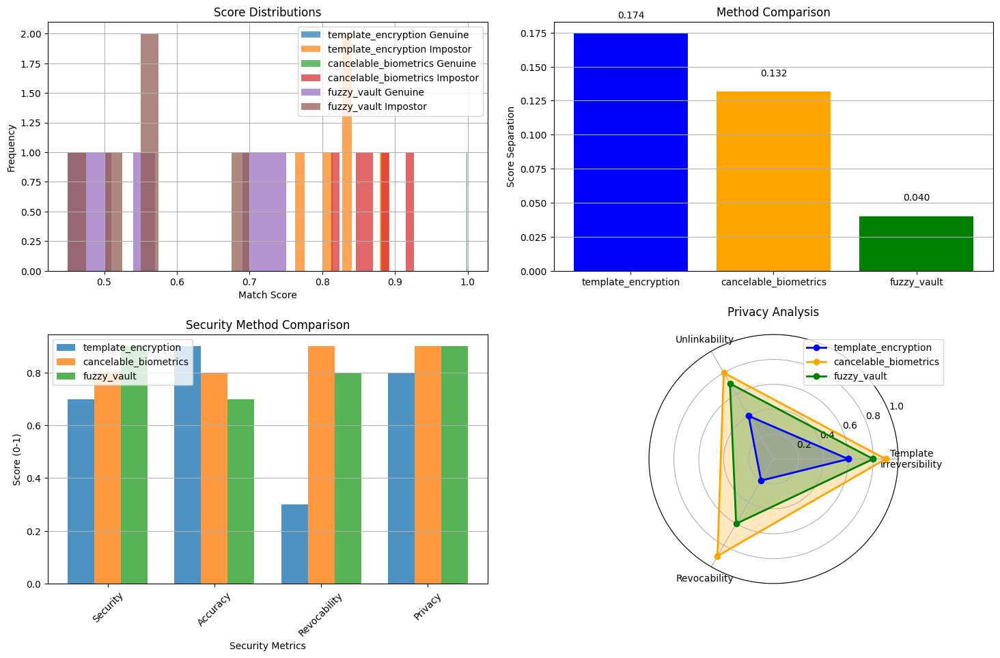


TESTING SECURE COMMUNICATION SYSTEM
=== Secure Wavelet Communication Demonstration ===
Secret message: 'TOP SECRET DATA!'
Message bits (128 bits): 01010100010011110101000000100000010100110100010101...
awgn (noise=0.05): BER=0.000, SNR=24.5dB, Success=False
  Extracted: 'TOP SECRET ...'
awgn (noise=0.1): BER=0.000, SNR=18.5dB, Success=False
  Extracted: 'TOP SECRET ...'
awgn (noise=0.2): BER=0.047, SNR=12.1dB, Success=False
  Extracted: 'TOP CEC:åT ...'
fading (noise=0.05): BER=0.320, SNR=-3.0dB, Success=False
  Extracted: '&~}ãò£_ÛÎâ...'
fading (noise=0.1): BER=0.398, SNR=-3.2dB, Success=False
  Extracted: '§Tå]¨ø...'
fading (noise=0.2): BER=0.352, SNR=-3.5dB, Success=False
  Extracted: 'J®C¢z?...'
interference (noise=0.05): BER=0.008, SNR=11.5dB, Success=False
  Extracted: 'POP SECRET ...'
interference (noise=0.1): BER=0.016, SNR=10.8dB, Success=False
  Extracted: 'ÐOP SECRET ...'
interference (noise=0.2): BER=0.039, SNR=8.9dB, Success=False
  Extracted: 'POP"CEGVET ...'


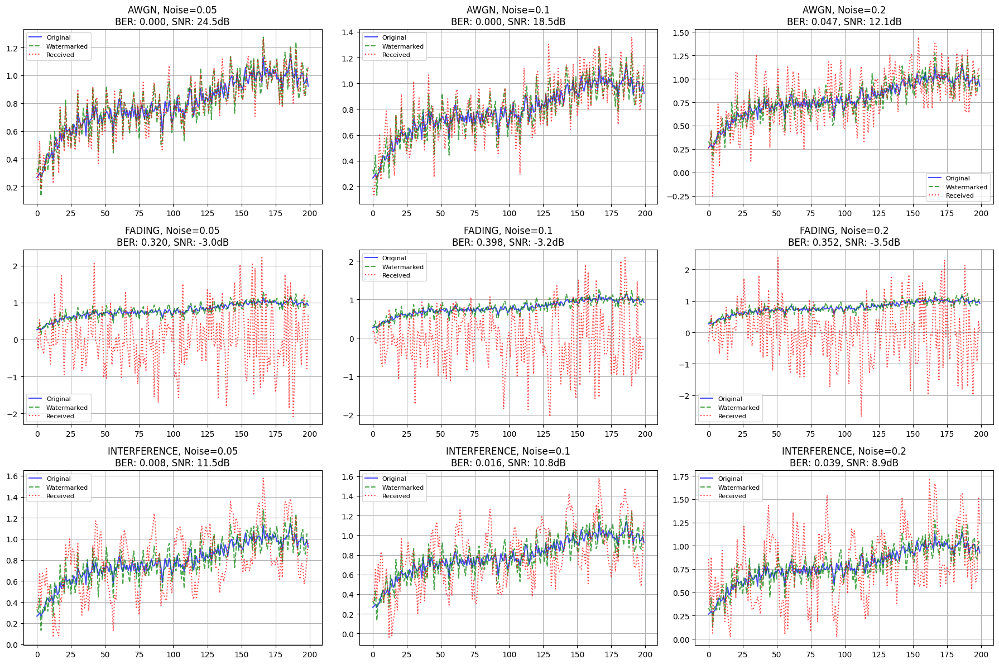

C:\Users\shouk\AppData\Local\Temp\ipykernel_23284\2797914897.py:271: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=1.0)


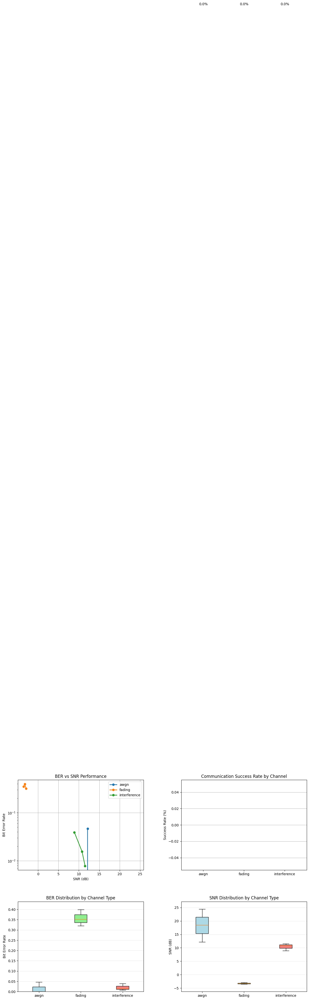


ANALYSIS SUMMARY
✓ Tested 10 biometric samples
✓ Evaluated 3 biometric protection methods
✓ Communication tested under 3 channel conditions

Biometric Security Results:
  template_encryption: Separation = 0.174
  cancelable_biometrics: Separation = 0.132
  fuzzy_vault: Separation = 0.040

Communication Results:
  awgn: 0/3 successful transmissions
  fading: 0/3 successful transmissions
  interference: 0/3 successful transmissions

ANALYSIS COMPLETE!


In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC


class SecureWaveletCommunication:
    def __init__(self, wavelet='db4', levels=3):
        self.wavelet = wavelet
        self.levels = levels
        self.channel_model = None
    
    def spread_spectrum_embedding(self, cover_signal, message_bits, spreading_factor=10):
        """Embed message using spread spectrum in wavelet domain"""
        coeffs = pywt.wavedec(cover_signal, self.wavelet, level=self.levels)
        
        np.random.seed(42)
        spreading_codes = []
        for _ in range(len(message_bits)):
            code = np.random.choice([-1, 1], size=spreading_factor)
            spreading_codes.append(code)
        
        modified_coeffs = [coeffs[0]]
        bit_index = 0
        for level, detail_coeff in enumerate(coeffs[1:], 1):
            if bit_index >= len(message_bits):
                modified_coeffs.append(detail_coeff)
                continue
            
            modified_detail = detail_coeff.copy()
            flat_detail = modified_detail.flatten()
            
            for i in range(0, len(flat_detail) - spreading_factor, spreading_factor):
                if bit_index >= len(message_bits):
                    break
                
                bit_value = 1 if int(message_bits[bit_index]) == 1 else -1
                spread_signal = bit_value * spreading_codes[bit_index]
                
                end_idx = min(i + spreading_factor, len(flat_detail))
                actual_length = end_idx - i
                flat_detail[i:end_idx] += 0.1 * spread_signal[:actual_length]
                
                bit_index += 1
            
            modified_coeffs.append(flat_detail.reshape(detail_coeff.shape))
        
        watermarked_signal = pywt.waverec(modified_coeffs, self.wavelet)
        return watermarked_signal, spreading_codes[:bit_index]
    
    def spread_spectrum_extraction(self, received_signal, spreading_codes, num_bits):
        """Extract message using spread spectrum correlation"""
        coeffs = pywt.wavedec(received_signal, self.wavelet, level=self.levels)
        
        extracted_bits = []
        bit_index = 0
        spreading_factor = len(spreading_codes[0]) if spreading_codes else 10
        
        for level, detail_coeff in enumerate(coeffs[1:], 1):
            if bit_index >= num_bits:
                break
            
            flat_detail = detail_coeff.flatten()
            
            for i in range(0, len(flat_detail) - spreading_factor, spreading_factor):
                if bit_index >= num_bits or bit_index >= len(spreading_codes):
                    break
                
                end_idx = min(i + spreading_factor, len(flat_detail))
                actual_length = end_idx - i
                received_segment = flat_detail[i:end_idx]
                
                if len(received_segment) == actual_length:
                    correlation = np.sum(received_segment * spreading_codes[bit_index][:actual_length])
                    extracted_bits.append('1' if correlation > 0 else '0')
                
                bit_index += 1
        
        return ''.join(extracted_bits)
    
    def simulate_channel_effects(self, signal, noise_level=0.1, channel_type='awgn'):
        """Simulate communication channel effects"""
        if channel_type == 'awgn':
            noise = np.random.normal(0, noise_level, signal.shape)
            return signal + noise
        elif channel_type == 'fading':
            h = np.random.rayleigh(1, signal.shape) * np.exp(1j * np.random.uniform(0, 2*np.pi, signal.shape))
            faded_signal = np.real(h) * signal
            noise = np.random.normal(0, noise_level, signal.shape)
            return faded_signal + noise
        elif channel_type == 'interference':
            t = np.linspace(0, 1, len(signal))
            interference = 0.3 * np.sin(2 * np.pi * 50 * t)
            noise = np.random.normal(0, noise_level, signal.shape)
            return signal + interference + noise
        else:
            return signal
    
    def demonstrate_secure_communication(self, cover_signal, secret_message):
        """Demonstrate secure communication system"""
        print("=== Secure Wavelet Communication Demonstration ===")
        print(f"Secret message: '{secret_message}'")
        
        message_bits = ''.join(format(ord(c), '08b') for c in secret_message)
        print(f"Message bits ({len(message_bits)} bits): {message_bits[:50]}...")
        
        watermarked_signal, spreading_codes = self.spread_spectrum_embedding(
            cover_signal, message_bits)
        
        channel_types = ['awgn', 'fading', 'interference']
        noise_levels = [0.05, 0.1, 0.2]
        results = {}
        
        plt.figure(figsize=(18, 12))
        
        for i, channel_type in enumerate(channel_types):
            results[channel_type] = {}
            for j, noise_level in enumerate(noise_levels):
                received_signal = self.simulate_channel_effects(
                    watermarked_signal, noise_level, channel_type)
                
                extracted_bits = self.spread_spectrum_extraction(
                    received_signal, spreading_codes, len(message_bits))
                
                extracted_message = ''
                for k in range(0, min(len(extracted_bits), len(message_bits)), 8):
                    byte = extracted_bits[k:k+8]
                    if len(byte) == 8:
                        try:
                            extracted_message += chr(int(byte, 2))
                        except ValueError:
                            extracted_message += '?'
                
                ber = sum(b1 != b2 for b1, b2 in 
                         zip(message_bits, extracted_bits)) / len(message_bits)
                
                signal_power = np.mean(watermarked_signal**2)
                noise_power = np.mean((watermarked_signal - received_signal)**2)
                snr = 10 * np.log10(signal_power / noise_power) if noise_power > 0 else float('inf')
                
                results[channel_type][noise_level] = {
                    'ber': ber,
                    'snr': snr,
                    'extracted_message': extracted_message,
                    'success': extracted_message == secret_message
                }
                
                subplot_idx = i * len(noise_levels) + j + 1
                plt.subplot(3, 3, subplot_idx)
                
                plt.plot(cover_signal[:200], 'b-', alpha=0.7, label='Original')
                plt.plot(watermarked_signal[:200], 'g--', alpha=0.7, label='Watermarked')
                plt.plot(received_signal[:200], 'r:', alpha=0.7, label='Received')
                
                plt.title(f'{channel_type.upper()}, Noise={noise_level}\n'
                         f'BER: {ber:.3f}, SNR: {snr:.1f}dB')
                plt.legend(fontsize=8)
                plt.grid(True)
                
                print(f"{channel_type} (noise={noise_level}): "
                      f"BER={ber:.3f}, SNR={snr:.1f}dB, "
                      f"Success={extracted_message == secret_message}")
                print(f"  Extracted: '{extracted_message[:20]}...'")
        
        plt.tight_layout()
        plt.savefig('./output/secure_wavelet_communication.png')
        plt.show()
        
        self._plot_communication_performance(results)
        
        return results
    
    def _plot_communication_performance(self, results):
        """Plot communication system performance - FIXED VERSION"""
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # Fix subplot spacing to eliminate whitespace
        plt.subplots_adjust(hspace=0.35, wspace=0.3, top=0.95, bottom=0.1)
        
        # BER vs SNR Performance
        ax = axes[0, 0]
        for channel_type, channel_results in results.items():
            snr_values = [data['snr'] for data in channel_results.values()]
            ber_values = [data['ber'] for data in channel_results.values()]
            ax.semilogy(snr_values, ber_values, 'o-', label=channel_type, linewidth=2)
        
        ax.set_xlabel('SNR (dB)')
        ax.set_ylabel('Bit Error Rate')
        ax.set_title('BER vs SNR Performance')
        ax.legend()
        ax.grid(True)
        
        # Success Rate Bar Chart
        ax = axes[0, 1]
        channel_names = list(results.keys())
        success_rates = []
        for channel_type in channel_names:
            successes = sum(1 for data in results[channel_type].values() if data['success'])
            total = len(results[channel_type])
            success_rates.append(successes / total * 100)
        
        bars = ax.bar(channel_names, success_rates, color=['blue', 'orange', 'green'])
        ax.set_ylabel('Success Rate (%)')
        ax.set_title('Communication Success Rate by Channel')
        ax.grid(True, axis='y')
        
        for bar, rate in zip(bars, success_rates):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                   f'{rate:.1f}%', ha='center', va='bottom')
        
        # FIXED BER Distribution Boxplot
        ax = axes[1, 0]
        all_bers = []
        labels = []
        for channel_type, channel_results in results.items():
            bers = [data['ber'] for data in channel_results.values()]
            all_bers.extend(bers)
            labels.extend([channel_type] * len(bers))
        
        unique_channels = list(results.keys())
        channel_bers = [[] for _ in unique_channels]
        for ber, label in zip(all_bers, labels):
            channel_idx = unique_channels.index(label)
            channel_bers[channel_idx].append(ber)
        
        # Create boxplot with proper y-limits
        bp1 = ax.boxplot(channel_bers, tick_labels=unique_channels, patch_artist=True)
        
        # Fix y-axis limits based on actual data
        all_ber_values = [item for sublist in channel_bers for item in sublist]
        if all_ber_values:
            y_min, y_max = min(all_ber_values), max(all_ber_values)
            y_range = y_max - y_min if y_max != y_min else y_max
            if y_range > 0:
                ax.set_ylim(max(0, y_min - 0.1 * y_range), y_max + 0.1 * y_range)
            else:
                ax.set_ylim(0, y_max * 1.1 if y_max > 0 else 1)
        
        # Color the boxes
        colors = ['lightblue', 'lightgreen', 'lightcoral']
        for patch, color in zip(bp1['boxes'], colors):
            patch.set_facecolor(color)
        
        ax.set_ylabel('Bit Error Rate')
        ax.set_title('BER Distribution by Channel Type')
        ax.grid(True, axis='y', alpha=0.3)
        
        # FIXED SNR Distribution Boxplot
        ax = axes[1, 1]
        channel_snrs = [[] for _ in unique_channels]
        for channel_type, channel_results in results.items():
            channel_idx = unique_channels.index(channel_type)
            # Filter out infinite SNR values
            snrs = [data['snr'] for data in channel_results.values() if not np.isinf(data['snr'])]
            channel_snrs[channel_idx] = snrs
        
        # Create boxplot with proper y-limits
        bp2 = ax.boxplot(channel_snrs, tick_labels=unique_channels, patch_artist=True)
        
        # Fix y-axis limits based on actual data
        all_snr_values = [item for sublist in channel_snrs for item in sublist]
        if all_snr_values:
            y_min, y_max = min(all_snr_values), max(all_snr_values)
            y_range = y_max - y_min if y_max != y_min else y_max
            if y_range > 0:
                ax.set_ylim(y_min - 0.1 * y_range, y_max + 0.1 * y_range)
            else:
                ax.set_ylim(0, y_max * 1.1 if y_max > 0 else 1)
        
        # Color the boxes
        for patch, color in zip(bp2['boxes'], colors):
            patch.set_facecolor(color)
        
        ax.set_ylabel('SNR (dB)')
        ax.set_title('SNR Distribution by Channel Type')
        ax.grid(True, axis='y', alpha=0.3)
        
        plt.tight_layout(pad=1.0)
        plt.savefig('./output/secure_communication_performance.png')
        plt.show()


if __name__ == "__main__":
    print("=== Comprehensive Secure Biometrics and Communication Testing ===")
    
    # Set random seed for reproducibility
    np.random.seed(42)
    
    # Generate synthetic biometric samples
    biometric_samples = []
    for i in range(10):
        if i < 5:
            # Genuine samples - similar pattern with small variations
            base_pattern = np.sin(np.linspace(0, 4*np.pi, 128)) + 0.5*np.cos(np.linspace(0, 2*np.pi, 128))
            noise = 0.1 * np.random.randn(128)
            sample = base_pattern + noise
        else:
            # Impostor samples - different pattern
            sample = np.random.randn(128) + np.sin(np.linspace(0, 6*np.pi, 128))
        biometric_samples.append(sample)
    
    # Test Biometric Security System
    print("\n" + "="*60)
    print("TESTING BIOMETRIC SECURITY SYSTEM")
    print("="*60)
    
    biometric_system = SecureBiometricSystem()
    security_results = biometric_system.demonstrate_security_analysis(biometric_samples)
    
    # Test Secure Communication System
    print("\n" + "="*60)
    print("TESTING SECURE COMMUNICATION SYSTEM")
    print("="*60)
    
    # Generate cover signal
    t = np.linspace(0, 2*np.pi, 1000)
    cover_signal = np.sin(t) + 0.5*np.sin(3*t) + 0.3*np.cos(5*t)
    cover_signal += 0.05 * np.random.randn(len(t))
    
    comm_system = SecureWaveletCommunication()
    secret_message = "TOP SECRET DATA!"
    
    comm_results = comm_system.demonstrate_secure_communication(cover_signal, secret_message)
    
    # Final Summary
    print("\n" + "="*60)
    print("ANALYSIS SUMMARY")
    print("="*60)
    print(f"✓ Tested {len(biometric_samples)} biometric samples")
    print(f"✓ Evaluated {len(security_results)} biometric protection methods")
    print(f"✓ Communication tested under {len(comm_results)} channel conditions")
    
    # Security Analysis Summary
    print("\nBiometric Security Results:")
    for method, data in security_results.items():
        print(f"  {method}: Separation = {data['separation']:.3f}")
    
    # Communication Analysis Summary
    print("\nCommunication Results:")
    for channel_type, channel_data in comm_results.items():
        success_count = sum(1 for data in channel_data.values() if data['success'])
        total_tests = len(channel_data)
        print(f"  {channel_type}: {success_count}/{total_tests} successful transmissions")
    
    print("\n" + "="*60)
    print("ANALYSIS COMPLETE!")
    print("="*60)